In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
import matplotlib.patches as mpatches
import h5py
import pickle
from scipy.integrate import simpson

In [2]:
def compact_exp_format(num):
    s = "{:.1e}".format(num)  # one decimal place
    base, exp = s.split("e")
    exp = int(exp)
    # Return a string that is already in math mode
    return r"{} \times 10^{{{}}}".format(base, exp)

In [3]:
from feedback_mimic import (
    Mtot_to_MDelta, get_some_quantities, get_spectra, get_realspace_profile, get_NFW_profile, comoving_distance
)

##### Power Spectrum Plots

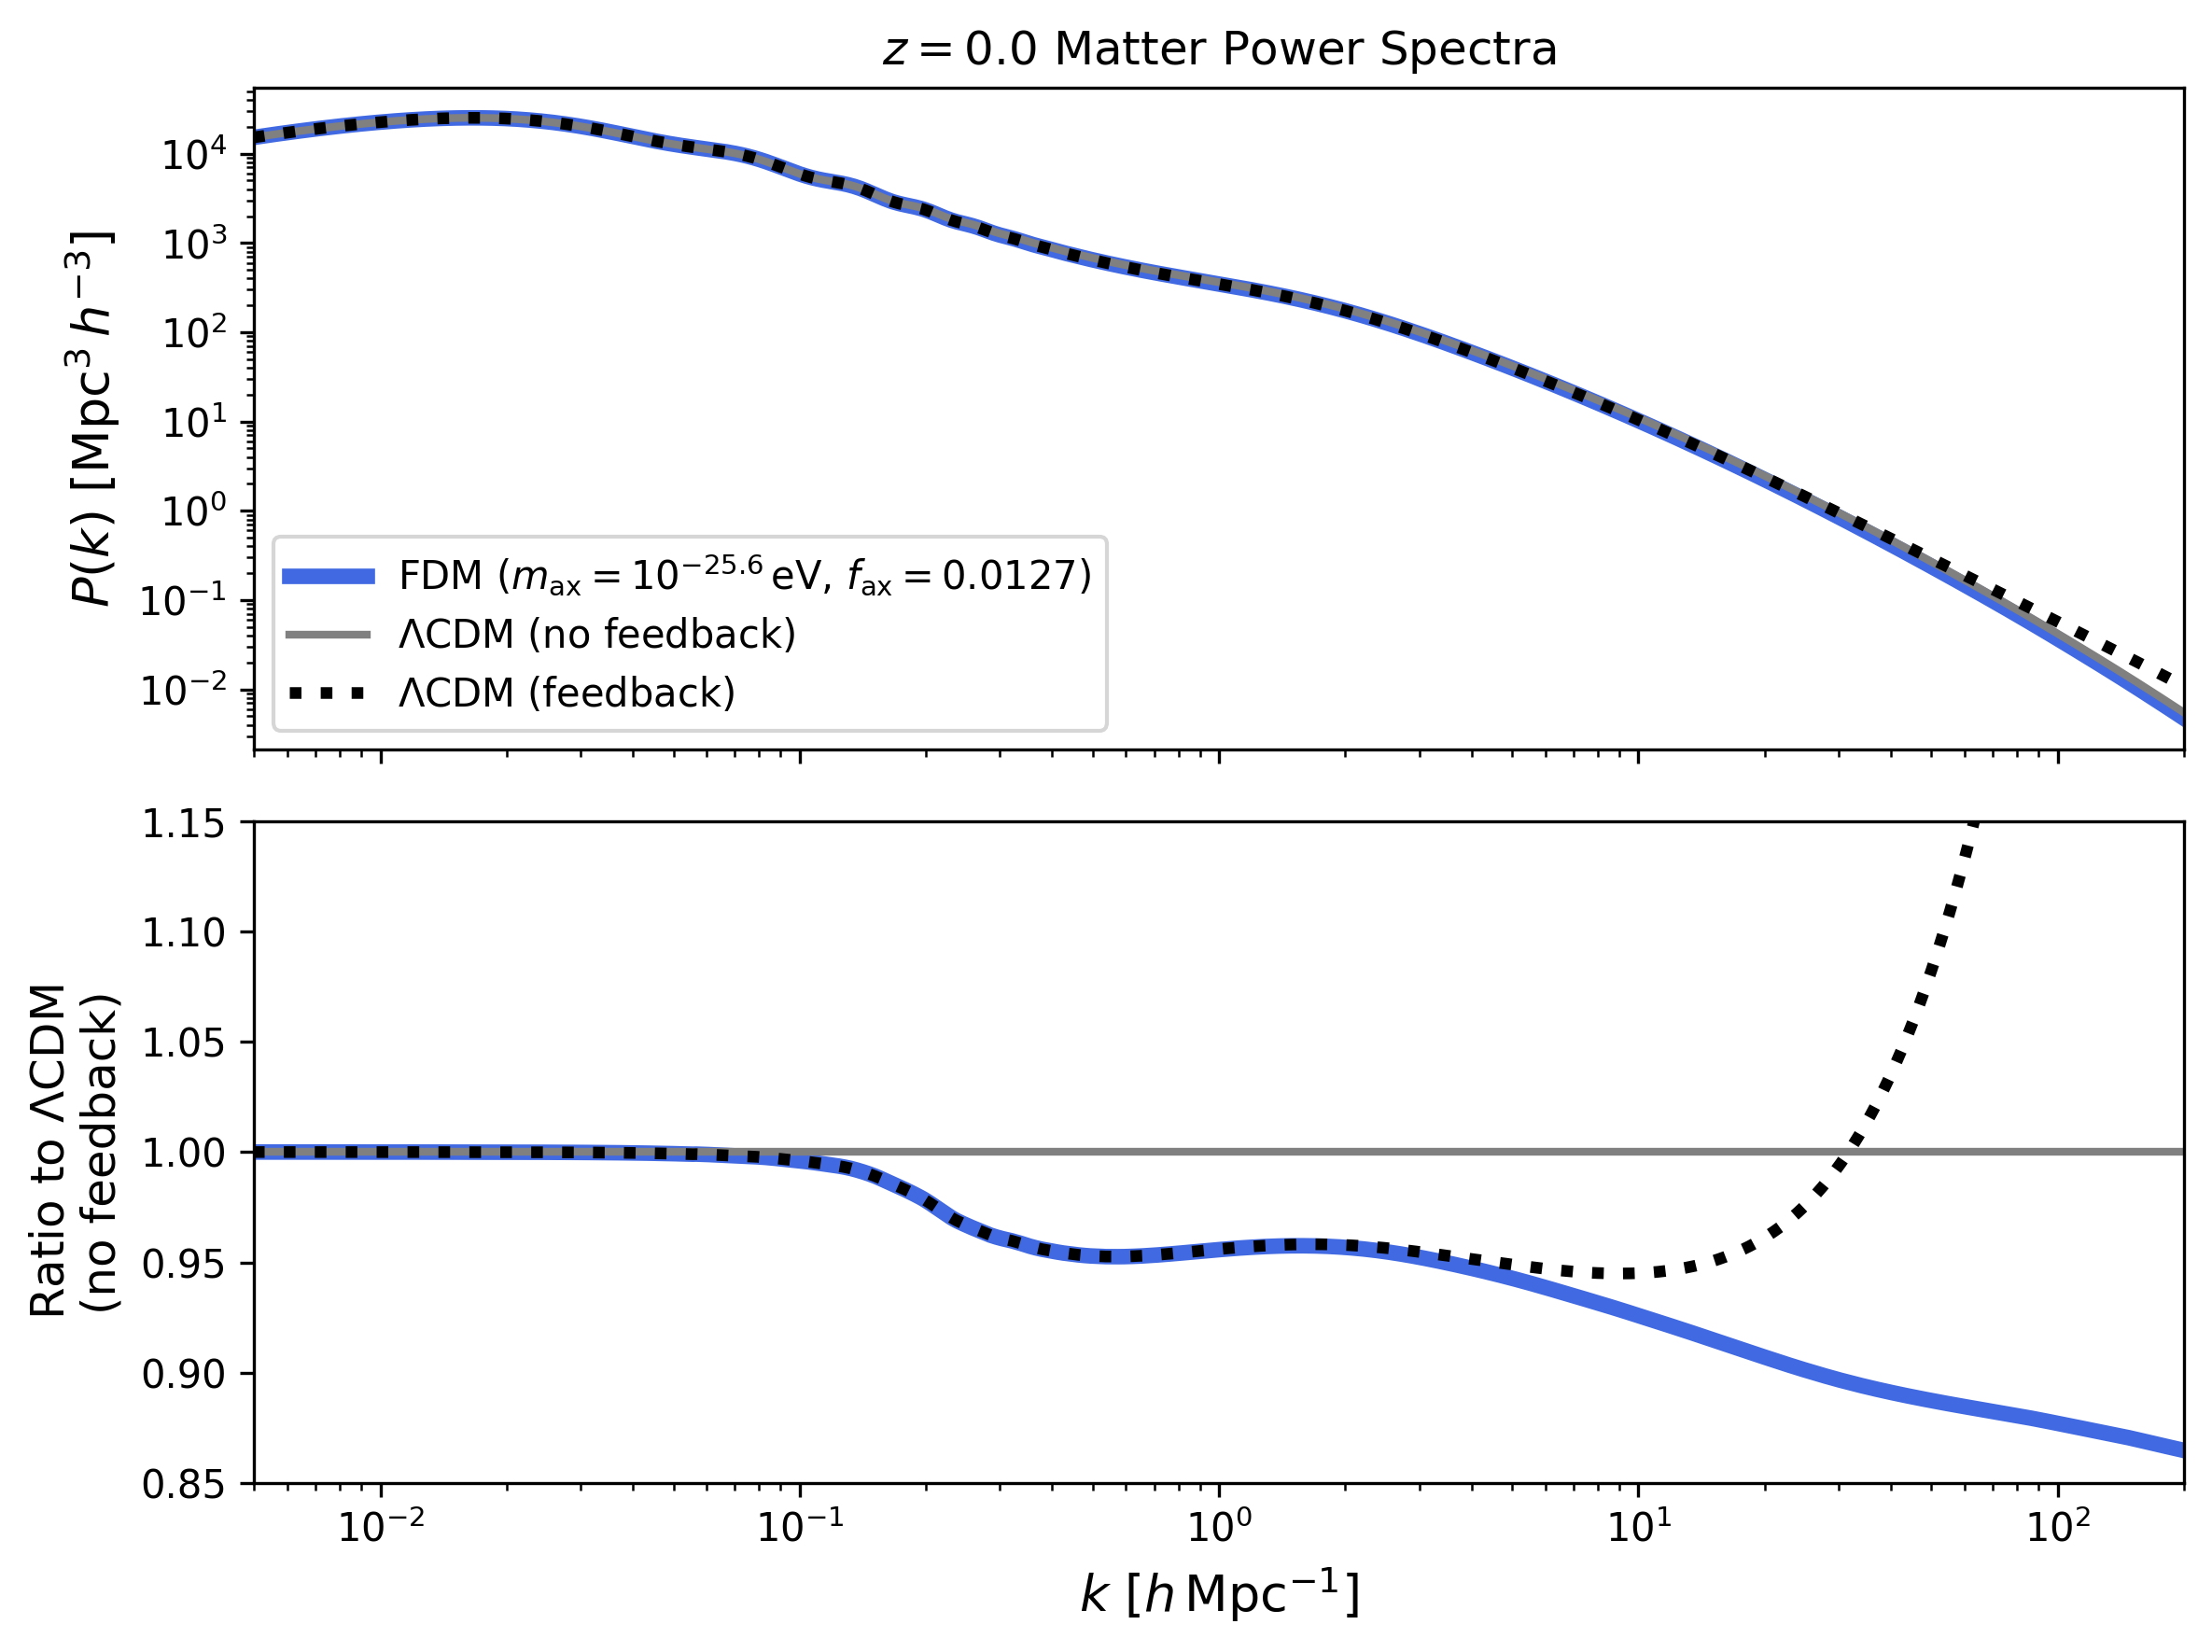

In [42]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), dpi=300, sharex=True, height_ratios=[1.0,1.0])

z = 0.0

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
with open(f"results/halo_model/{z}_data_FDM_full2h_preferred.pkl", "rb") as f:
    data_FDM_preferred = pickle.load(f)

r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
k_arr_HMCode = data_LCDM['power_spec_dic']['k']
M_arr = data_LCDM['M']
K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1/min(K_ARR)), 1500)

# FDM preferred
ax1.plot(k_arr_HMCode, data_FDM_preferred['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
# ΛCDM baseline
ax1.plot(k_arr_HMCode, data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
ax2.plot(k_arr_HMCode, data_LCDM['P'] / data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
# P^target = P_FDM * S_cooling
M200c_arr, r200c_arr = Mtot_to_MDelta(
    data_LCDM, r_v, M_arr, K_ARR, R_ARR, Del=200, reference_density="critical"
)
f_cga = 0.09 * (2.5e11 / M200c_arr)**0.6
R_h   = 0.015 * r200c_arr

u_cga_HMCodek = f_cga[:, None] * np.exp(-(k_arr_HMCode[None, :] * R_h[:, None])**2)
u_cooled = u_cga_HMCodek + (1 - f_cga[:, None]) * data_LCDM['utilde']
u_cooled[M_arr < 2.5e11] = data_LCDM['utilde'][M_arr < 2.5e11]
S_cooling = get_spectra(data_LCDM, u_cooled, full_output=False) / data_LCDM['P']

ax1.plot(k_arr_HMCode, data_FDM_preferred['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')

ax2.set_xlabel(r'$k$ $[h\,\text{Mpc}^{-1}]$', fontsize=13)
ax1.set_ylabel(r'$P(k)$ $[\text{Mpc}^{3}\,h^{-3}]$', fontsize=13)
ax2.set_ylabel(r'Ratio to $\Lambda$CDM' + '\n(no feedback)', fontsize=12)
ax1.set_title(r'$z=0.0$ Matter Power Spectra')
ax2.set_xlim(5e-3, 2e2)
ax2.set_ylim(0.85, 1.15)
ax2.set_xscale('log')
ax1.set_yscale('log')
ax1.legend(loc='lower left')

plt.tight_layout()
plt.show()

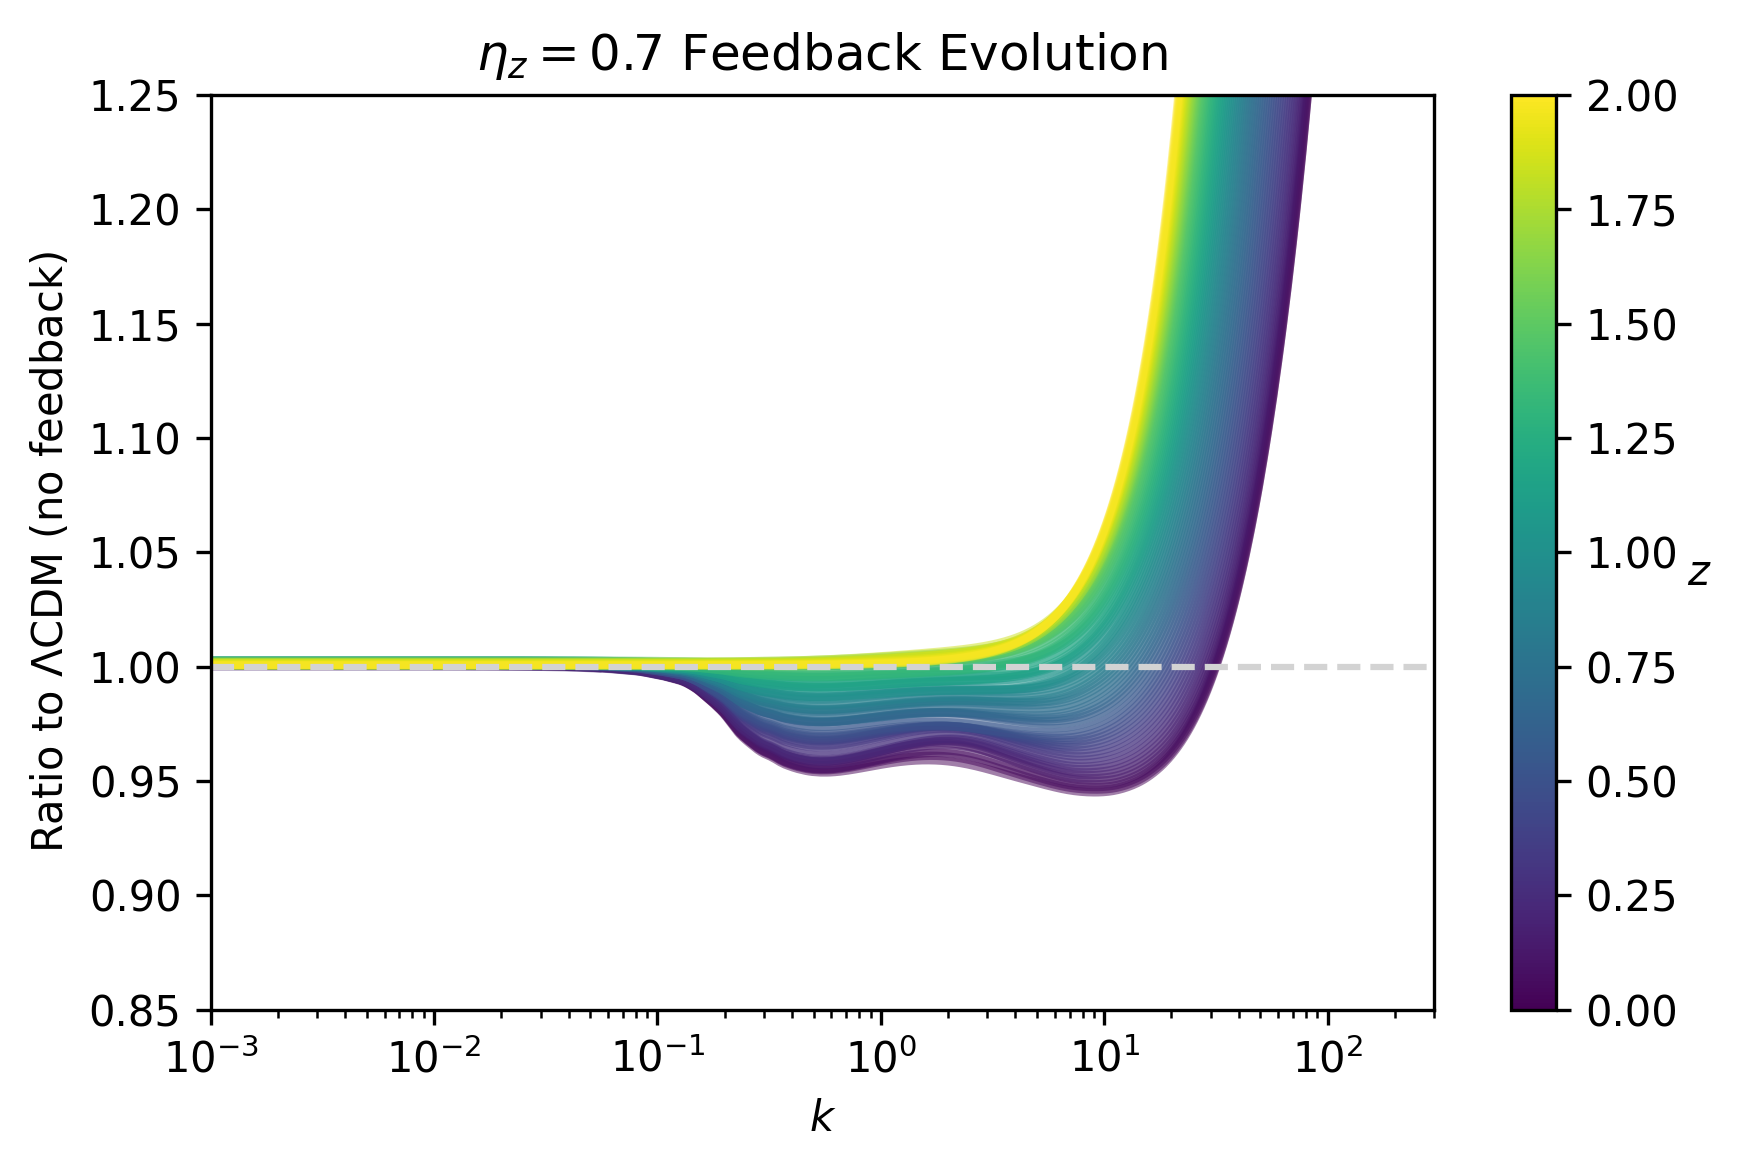

In [5]:
fig, ax1 = plt.subplots(1, 1, figsize=(6, 4), dpi=300)

gamma_val = 0.0
etaz = 0.7

K_ARR  = np.logspace(-6, 6, 8192)
R_ARR  = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)

z_arr      = np.linspace(0.0, 2.0, 81)
#z_arr = [0.0,0.5,1.0,1.5,2.0]
cmap = plt.cm.viridis
colors = cmap(np.linspace(0, 1, len(z_arr)))

for z, color in zip(z_arr, colors):
    with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data_LCDM = pickle.load(f)
    k_arr_HMCode = data_LCDM['power_spec_dic']['k']

    feedback_model = f"etaz{etaz}_preferred_cooled"
    baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
    #baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]

    ax1.semilogx(k_arr_HMCode, baryonic_profile[-1]['P']/data_LCDM['P'], c=color, ls='-',lw=2.,alpha=0.5)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0.0, vmax=2.0))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax1)
cbar.set_label(r'$z$', rotation=0, labelpad=5)

ax1.axhline(1.0, c='lightgray', ls='--')

ax1.set_xlabel(r'$k$')
ax1.set_ylabel(r'Ratio to $\Lambda$CDM (no feedback)')

ax1.set_ylim(0.85,1.25)
ax1.set_xlim(1e-3,3e2)
ax1.set_title(fr"$\eta_z = {etaz}$ Feedback Evolution")

plt.tight_layout()
plt.show()

##### Profile Plots

/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")
/tmp/ipykernel_2940391/3895193278.py:30: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
/tmp/ipykernel_2940391/3895193278.py:33: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])


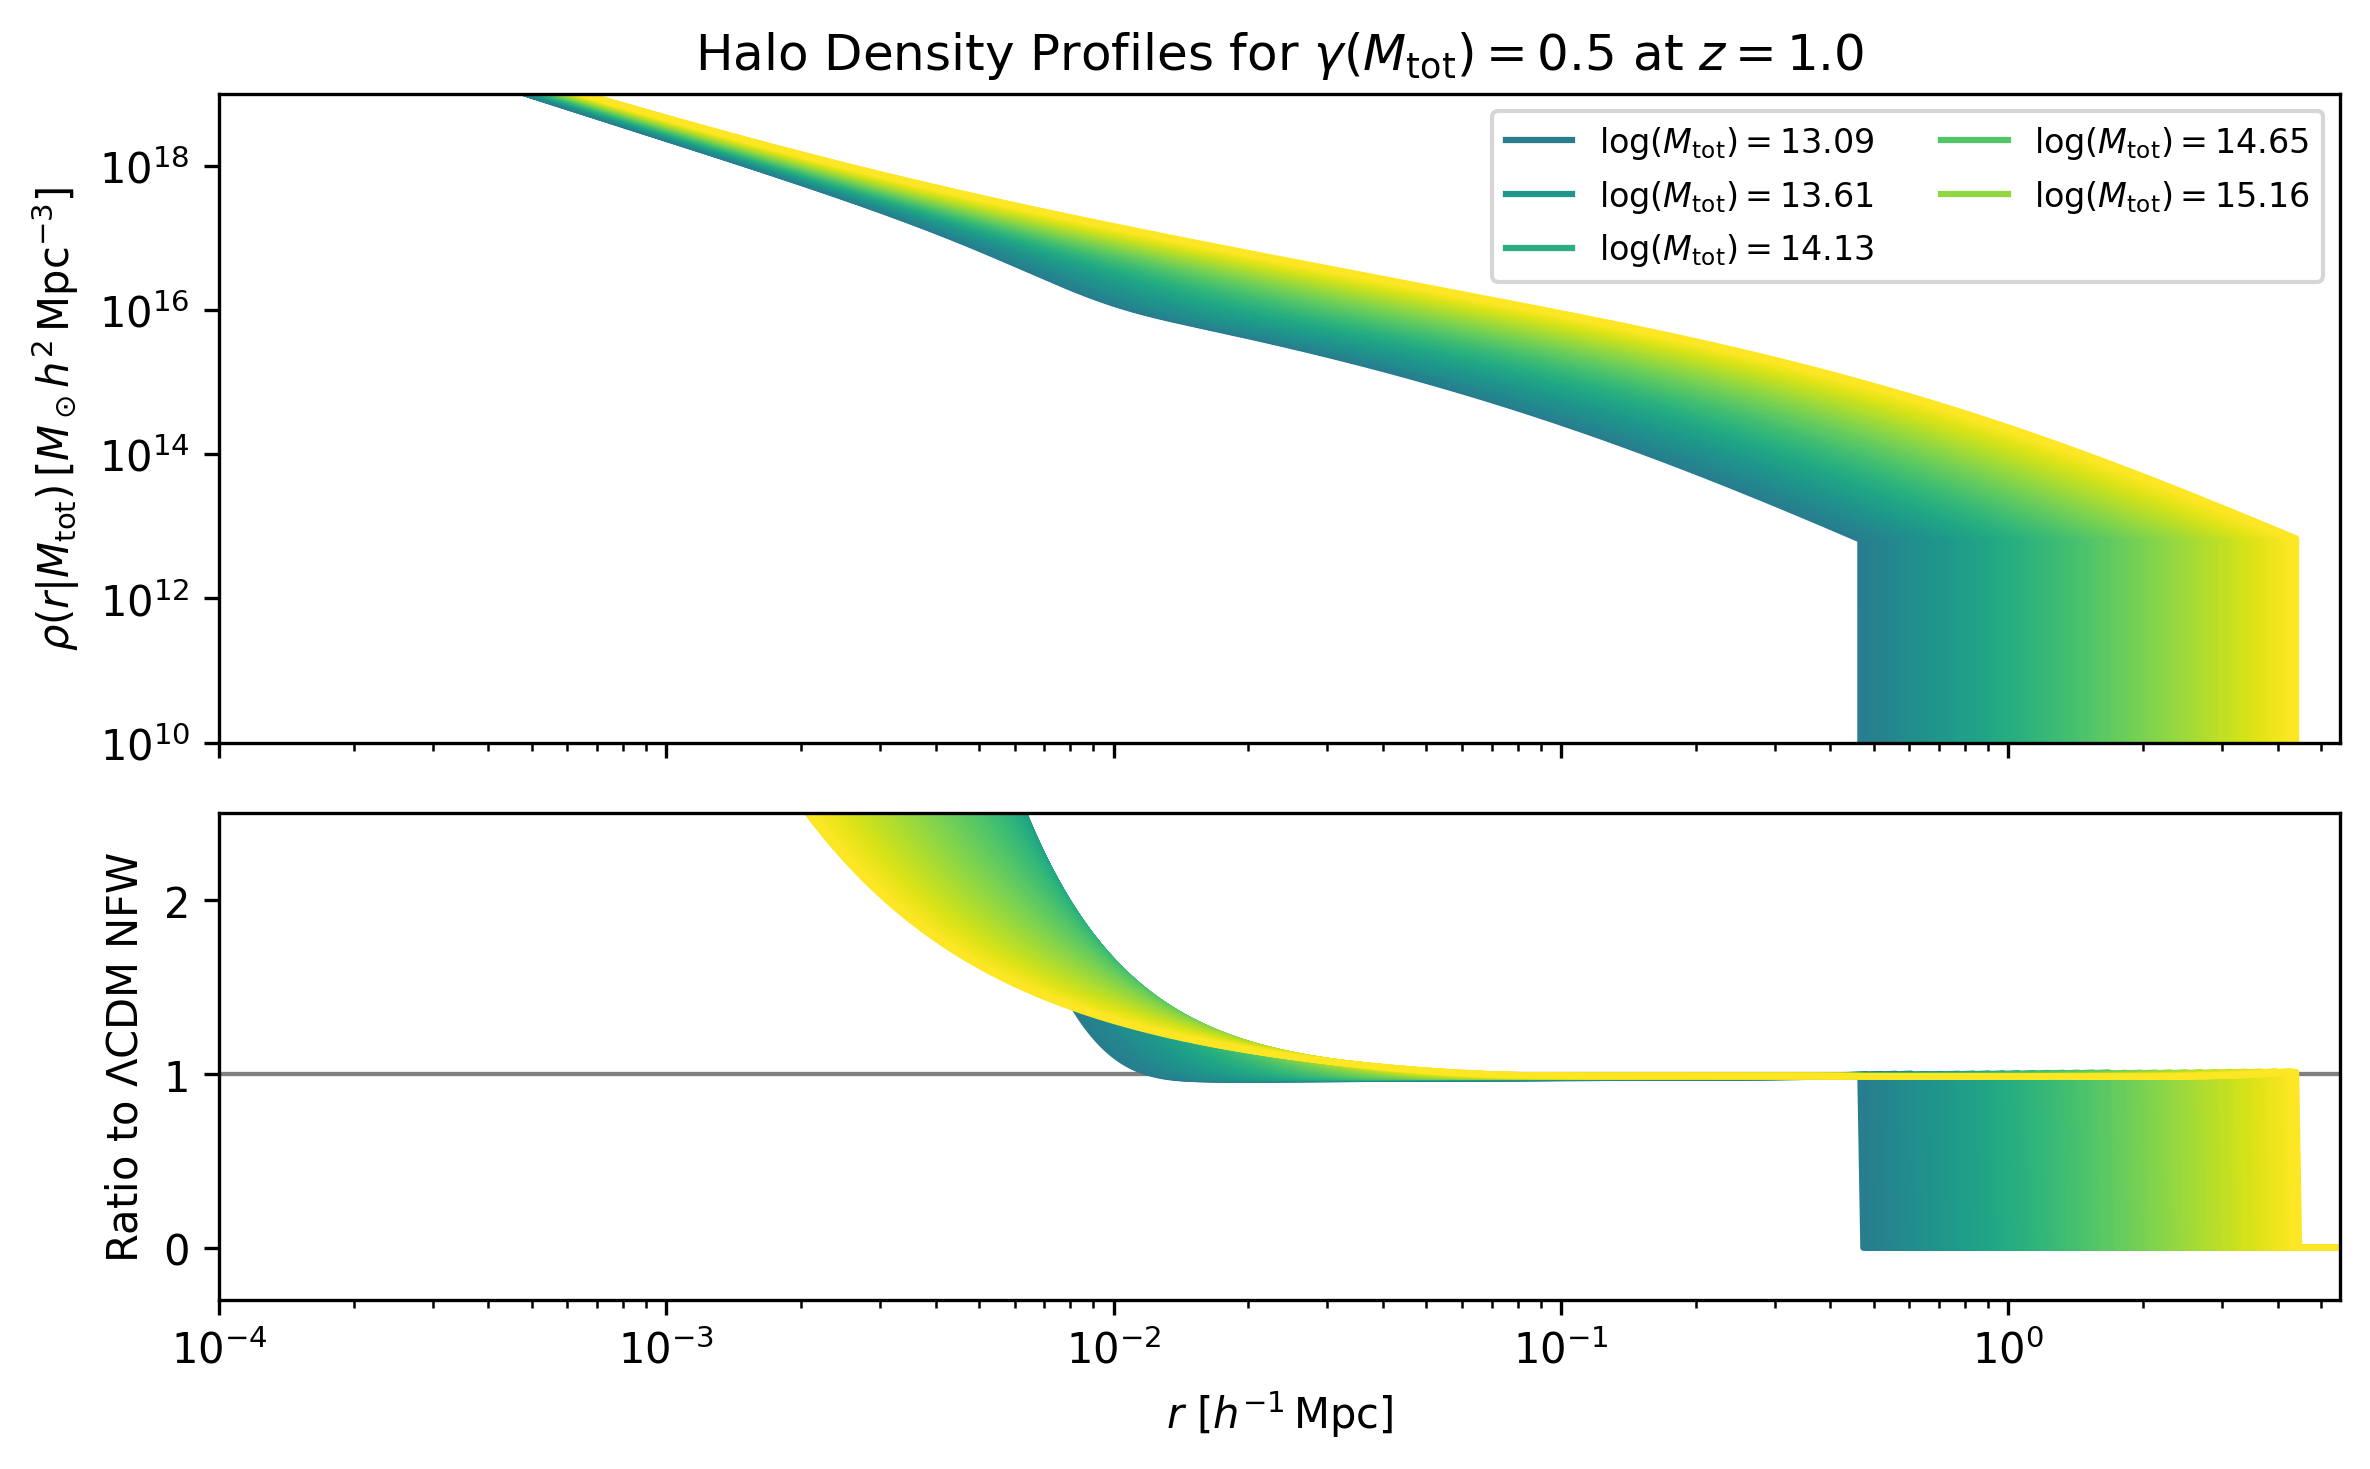

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), dpi=300, sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)
k_arr = np.logspace(-6, 6, 8192)
r_arr = np.logspace(-4, np.log10(1/min(k_arr)), 1500)

gamma_val = 0.5
etaz = 0.7
z = 1.0
feedback_model = f"etaz{etaz}_preferred_cooled"
keys = np.arange(np.size(data_LCDM['M'])) # M values
keys_labels = [0,31,62,93,125,156,187,218,249] # M values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
rho_NFW = get_realspace_profile(get_NFW_profile(k_arr=k_arr, r_s=r_s, r_v=r_v, r_t=max(r_arr) * r_v/r_v), 
                                r_t=max(r_arr) * r_v/r_v, r_arr=r_arr, k_arr=k_arr, M_arr=data_LCDM['M'])

#baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]
for m_index in keys[125:]:
    if m_index in keys_labels:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
    else:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])
#print(np.round(baryonic_profile[-1]['M_total_enclosed']/M_arr,4))

ax1.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
ax2.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
#ax2.set_ylim(0.5,1.5)
#ax1.set_ylim(1e12,1e19)
ax2.set_ylim(-0.3,2.5)
ax1.set_ylim(1e10,1e19)

ax2.set_ylabel(r'Ratio to $\Lambda$CDM NFW')
ax2.set_xscale("log")
ax2.set_yscale("linear")
ax1.set_yscale("log")
ax1.set_ylabel(r'$\rho(r|M_\text{tot}) \, [M_\odot h^2\,\text{Mpc}^{-3} ]$')
ax2.set_xlabel(r'$r$ $[h^{-1}\,\text{Mpc}]$')

ax1.set_title(rf'Halo Density Profiles for $\gamma(M_\text{{tot}}) = {gamma_val}$ at $z={z}$')
ax1.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

##### Cluster Counts Plot

LCDM_hat0.0: N_sel=23663
LCDM_hat0.5: N_sel=24148
LCDM_hat1.0: N_sel=24359
LCDM: N_sel=26303
FDM_preferred: N_sel=25300


/tmp/ipykernel_363585/3617513077.py:393: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


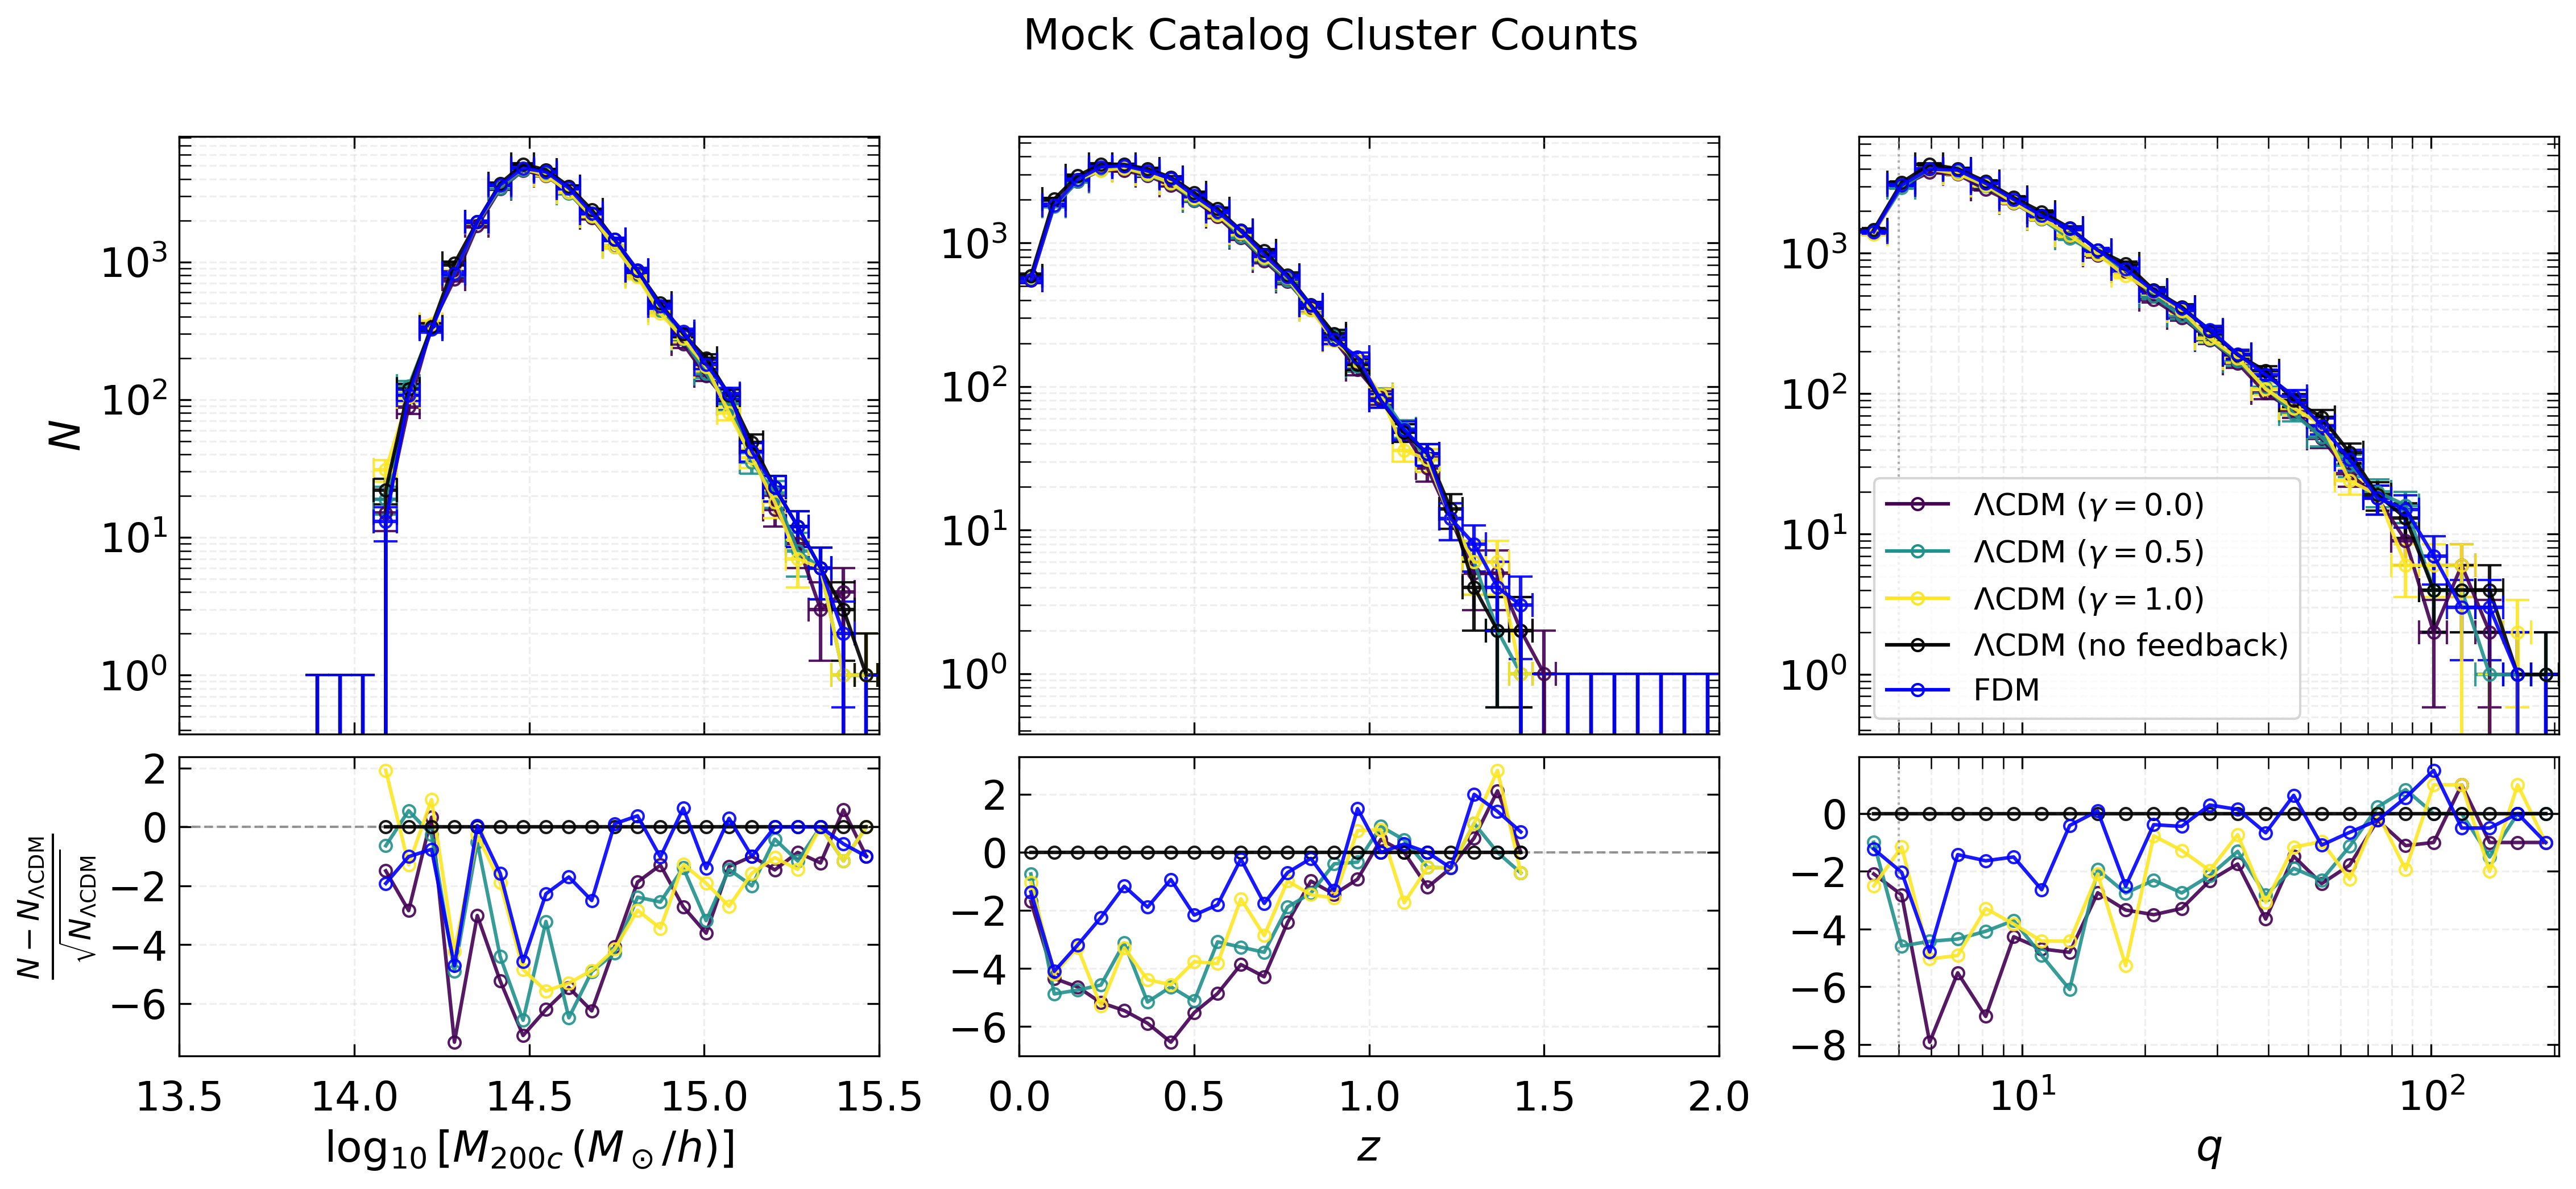

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%matplotlib inline

# ──────────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────────

CATALOG_DIR = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs"
SEED = 42

keys = [0.0,0.5,1.0] # gamma values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))
HMF_TYPES = [
    'LCDM_hat0.0',
    'LCDM_hat0.5',
    'LCDM_hat1.0',
    'LCDM',
    'FDM_preferred',
]

COLORS = [
    color_dict[0.0],
    color_dict[0.5],
    color_dict[1.0],
    'k',
    'b',
]

LABELS = [
    r'$\Lambda$CDM ($\gamma=0.0$)',
    r'$\Lambda$CDM ($\gamma=0.5$)',
    r'$\Lambda$CDM ($\gamma=1.0$)',
    r'$\Lambda$CDM (no feedback)',
    r'FDM',
]

N_BINS_M = 25
N_BINS_Z = 30
N_BINS_Q = 25

label_size = 17
title_size = 18
legend_size = 13

q_type = 'q_true'

# ──────────────────────────────────────────────────────────────────────────────
# STYLING
# ──────────────────────────────────────────────────────────────────────────────

def style_ax(ax):

    ax.tick_params(
        axis='x',
        which='both',
        length=5,
        direction='in',
        pad=10
    )

    ax.tick_params(
        axis='y',
        which='both',
        length=5,
        direction='in',
        pad=5
    )

    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

    plt.setp(
        ax.get_yticklabels(),
        rotation='horizontal',
        fontsize=label_size
    )

    plt.setp(
        ax.get_xticklabels(),
        fontsize=label_size
    )

    ax.grid(
        visible=True,
        which='both',
        alpha=0.2,
        linestyle='--'
    )


# ──────────────────────────────────────────────────────────────────────────────
# LOAD CATALOGS
# ──────────────────────────────────────────────────────────────────────────────

cats = {}

for hmf_type in HMF_TYPES:

    path = (
        f"{CATALOG_DIR}/"
        f"{hmf_type.replace('.', 'p')}_mock_seed{SEED}.pkl"
    )

    with open(path, "rb") as f:
        cats[hmf_type] = pickle.load(f)

    print(f"{hmf_type}: N_sel={cats[hmf_type]['n_selected']}")

# ──────────────────────────────────────────────────────────────────────────────
# BINNING
# ──────────────────────────────────────────────────────────────────────────────

ref = cats['LCDM']

M_edges = np.logspace(
    np.log10(ref['M200c_true'].min() * 0.6),
    np.log10(ref['M200c_true'].max() * 1.1),
    N_BINS_M + 1
)

z_edges = np.linspace(
    0.0,
    2.0,
    N_BINS_Z + 1
)

q_edges = np.logspace(
    np.log10(ref['Q_TH'] * 0.8),
    np.log10(ref[q_type].max() * 1.1),
    N_BINS_Q + 1
)

M_centres = 0.5 * (M_edges[1:] + M_edges[:-1])
z_centres = 0.5 * (z_edges[1:] + z_edges[:-1])
q_centres = 0.5 * (q_edges[1:] + q_edges[:-1])

# plotting coordinates

M_x = np.log10(M_centres)
z_x = z_centres
q_x = q_centres

# ──────────────────────────────────────────────────────────────────────────────
# HORIZONTAL BIN-WIDTH ERRORS
# ──────────────────────────────────────────────────────────────────────────────

M_xerr = np.vstack([
    M_x - np.log10(M_edges[:-1]),
    np.log10(M_edges[1:]) - M_x
])

z_xerr = np.vstack([
    z_x - z_edges[:-1],
    z_edges[1:] - z_x
])

q_xerr = np.vstack([
    q_x - q_edges[:-1],
    q_edges[1:] - q_x
])

# ──────────────────────────────────────────────────────────────────────────────
# HISTOGRAMS
# ──────────────────────────────────────────────────────────────────────────────

counts = {}

for hmf_type in HMF_TYPES:

    c = cats[hmf_type]

    counts[hmf_type] = {
        'M': np.histogram(c['M200c_true'], bins=M_edges)[0].astype(float),
        'z': np.histogram(c['z'], bins=z_edges)[0].astype(float),
        'q': np.histogram(c[q_type], bins=q_edges)[0].astype(float),
    }

n_lcdm = counts['LCDM']

# ──────────────────────────────────────────────────────────────────────────────
# FIGURE
# ──────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 7),
    dpi=300,
    gridspec_kw={
        'height_ratios': [1, 0.5],
        'hspace': 0.05,
    }
)

(ax_M, ax_z, ax_q), (ax_dM, ax_dz, ax_dq) = axes

top_axes = [ax_M, ax_z, ax_q]
bot_axes = [ax_dM, ax_dz, ax_dq]

# ──────────────────────────────────────────────────────────────────────────────
# PLOTTING
# ──────────────────────────────────────────────────────────────────────────────

for hmf_type, color, label in zip(HMF_TYPES, COLORS, LABELS):

    n = counts[hmf_type]

    # -------------------------------------------------------------------------
    # TOP ROW
    # -------------------------------------------------------------------------

    for ax, vals, x, xerr in [

        (ax_M, n['M'], M_x, M_xerr),
        (ax_z, n['z'], z_x, z_xerr),
        (ax_q, n['q'], q_x, q_xerr),

    ]:

        ax.errorbar(
            x,
            vals,
            xerr=xerr,
            yerr=np.sqrt(np.maximum(vals, 1)),
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            capsize=5,
            color=color,
            alpha=0.9,
            label=label
        )

    # -------------------------------------------------------------------------
    # BOTTOM ROW
    # -------------------------------------------------------------------------

    for ax, vals, ref_vals, x in [

        (ax_dM, n['M'], n_lcdm['M'], M_x),
        (ax_dz, n['z'], n_lcdm['z'], z_x),
        (ax_dq, n['q'], n_lcdm['q'], q_x),

    ]:

        safe_ref = np.where(ref_vals > 0, ref_vals, np.nan)

        delta_sigma = (vals - ref_vals) / np.sqrt(safe_ref)

        ax.plot(
            x,
            delta_sigma,
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            color=color,
            alpha=0.9,
        )

# ──────────────────────────────────────────────────────────────────────────────
# TOP ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in top_axes:

    style_ax(ax)

    ax.set_yscale('log')

    ax.tick_params(
        labelbottom=False
    )

top_axes[0].set_ylabel(
        r'$N$',
        size=title_size
    )

# q axis

ax_q.set_xscale('log')

ax_q.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# BOTTOM ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in bot_axes:

    style_ax(ax)

    ax.axhline(
        0,
        color='k',
        lw=1,
        ls='--',
        alpha=0.4
    )

bot_axes[0].set_ylabel(
    r'$\frac{N-N_{\Lambda\rm CDM}}{\sqrt{N_{\Lambda\rm CDM}}}$',
    size=title_size
)

ax_dM.set_xlabel(
    r'$\log_{10}[M_{200c}\,(M_\odot/h)]$',
    size=title_size
)

ax_dz.set_xlabel(
    r'$z$',
    size=title_size
)

ax_dq.set_xlabel(
    r'$q$',
    size=title_size
)

ax_dq.set_xscale('log')

ax_dq.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# AXIS LIMITS
# ──────────────────────────────────────────────────────────────────────────────

ax_M.set_xlim(M_x.min(), M_x.max())
ax_dM.set_xlim(M_x.min(), M_x.max())

ax_z.set_xlim(z_edges[0], z_edges[-1])
ax_dz.set_xlim(z_edges[0], z_edges[-1])

ax_q.set_xlim(q_edges[0], q_edges[-1])
ax_dq.set_xlim(q_edges[0], q_edges[-1])

# optional redshift ticks

ax_M.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_dM.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_z.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
ax_dz.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])

# ──────────────────────────────────────────────────────────────────────────────
# LEGEND
# ──────────────────────────────────────────────────────────────────────────────

handles = [
    Line2D(
        [0],
        [0],
        color=c,
        lw=1.5,
        marker='o',
        markersize=5,
        fillstyle='none',
        label=l
    )
    for c, l in zip(COLORS, LABELS)
]

ax_q.legend(
    handles=handles,
    loc='lower left',
    frameon=True,
    fontsize=legend_size
)

plt.suptitle("Mock Catalog Cluster Counts", fontsize=title_size)
plt.tight_layout()
plt.show()

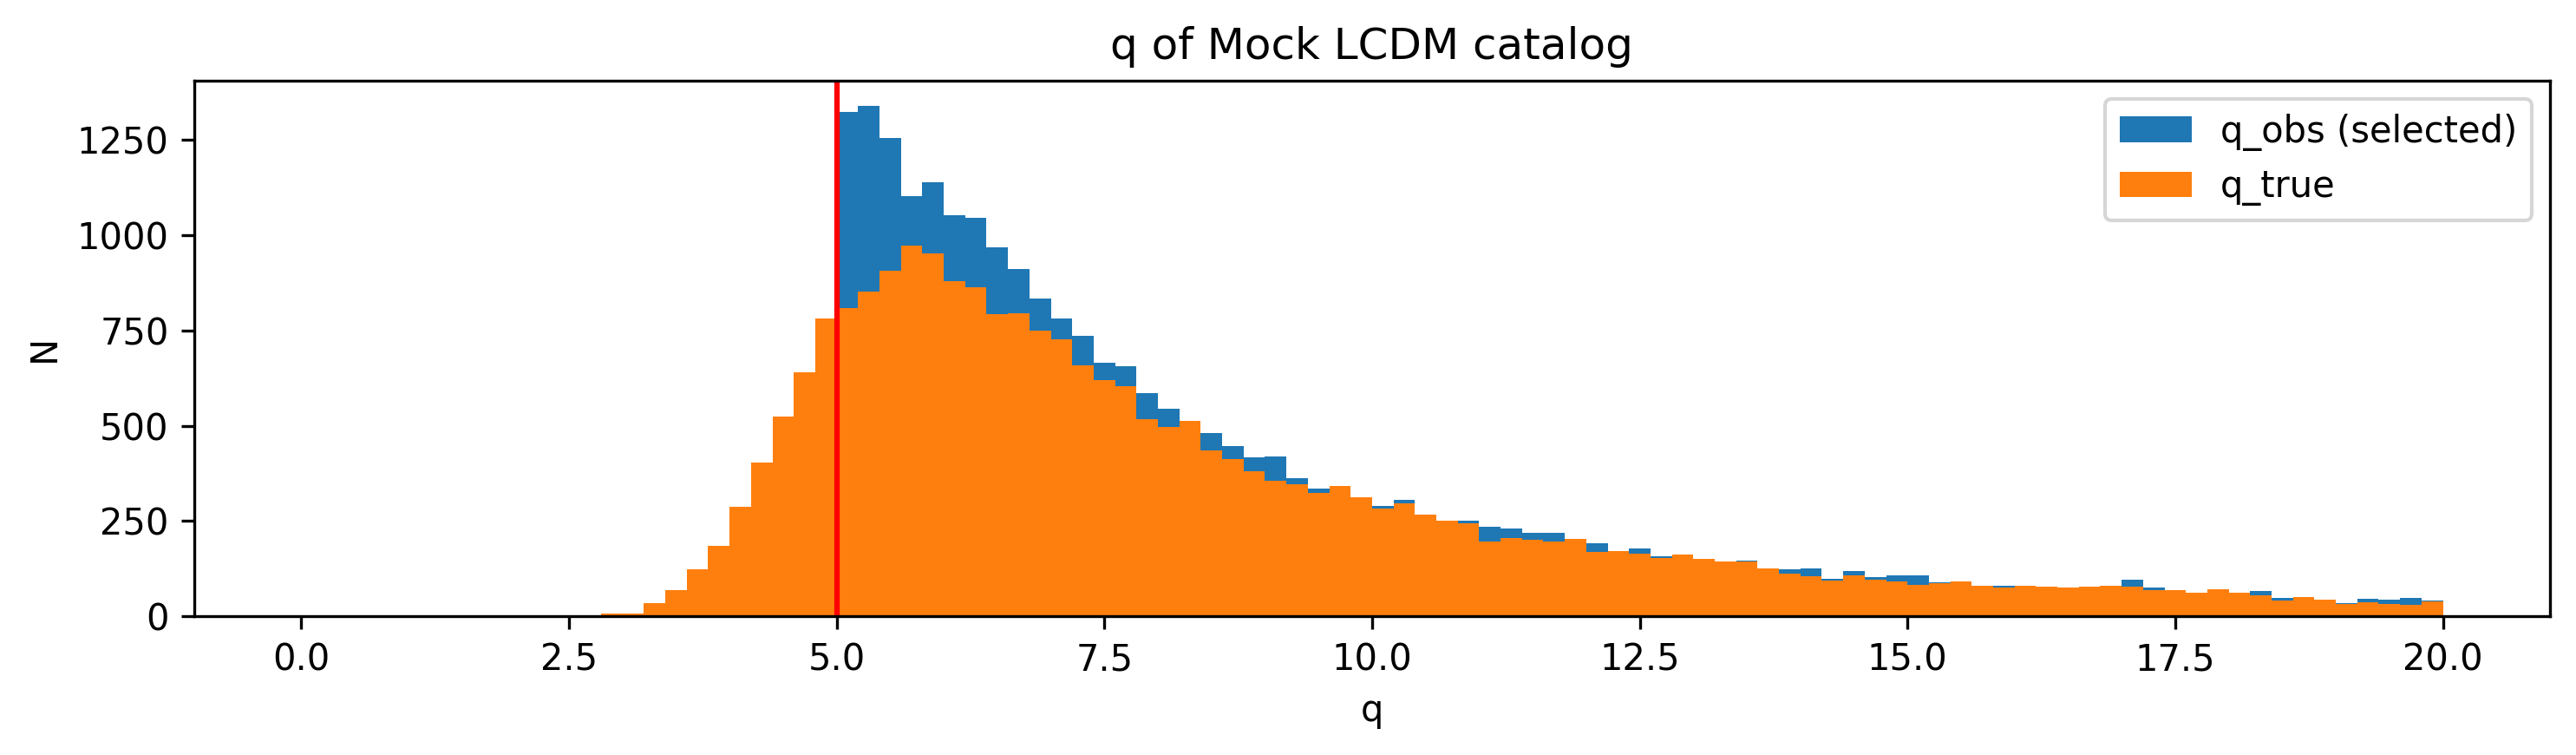

In [4]:
fig, axes = plt.subplots(1, 1, figsize=(10, 3), dpi=300)

axes.hist(cats['LCDM']['q_obs'], bins=100, range=(0, 20), label='q_obs (selected)')
axes.hist(cats['LCDM']['q_true'], bins=100, range=(0, 20), label='q_true')
#axes.hist(cats['LCDM']['q_mean'], bins=100, range=(0, 20), label='q_mean')
axes.axvline(cats['LCDM']['Q_TH'], color='r')

axes.set_title("q of Mock LCDM catalog")
axes.set_xlabel("q")
axes.set_ylabel("N")
axes.legend()

plt.tight_layout()
plt.show()

##### Likelihood Code

In [23]:
import pickle
import numpy as np
import os
import cosmocnc_axionHMcode_jax.cosmocnc_jax as cosmocnc
from wl_likelihoods import logP_gt_all
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import (
    func_axionHMcode_D_z_unnorm_int,
    func_axionHMcode_D_z_unnorm)
from astropy.cosmology import FlatLambdaCDM
from scipy.integrate import simpson
import jax
import jax.numpy as jnp

h_fid       = 0.68
omega_b_fid = 0.0226576
ns_fid      = 0.965

omega_m_fid = 0.143344
#logAs_fid   = np.log(2.1e-09 * 1e10)
sigma_8_fid = 0.825264573 # found from axionHMcode

_SURVEY_SR  = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_sr_so_sim.py"
_SURVEY_CAT = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_cat_so_sim.py"

Z_ARR        = np.linspace(0.0, 2.0, 81)
Z_ARR = Z_ARR[Z_ARR > 0]

In [24]:
# Precompute a bunch of quantities so we dont have to do it on the fly, and can just interpolate
_astropy_cosmo_fid = FlatLambdaCDM(H0=h_fid*100., Om0=omega_m_fid/h_fid**2)
_omega_m_grid      = np.linspace(0.05, 0.30, 50)
_Om0_grid          = _omega_m_grid / h_fid**2
_z_table           = np.concatenate([np.linspace(1e-6, 1., 500), np.linspace(1., 100., 500)])
_z_source_bins     = np.array([0.285, 0.476, 0.743, 0.942])

_G_SI    = 6.674e-11
_c_SI    = 2.998e8
_Mpc_m   = 3.0857e22
_Msol_kg = 1.989e30

_cache_path = "/home/jange/scratch/FeedbackMimic/results/mcmc/MCMC_GRID_CACHE.pkl"
if os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _G_a_grid, _D_table, _norm_grid, _DA_table, _Sigma_crit_table = pickle.load(f)
    print("Loaded precomputed tables from cache")
else:
    print("Precomputing tables (one-time cost)...")
    _G_a_grid  = np.array([
        func_axionHMcode_D_z_unnorm_int(
            0., Om0,
            lambda z, c=FlatLambdaCDM(H0=h_fid*100., Om0=Om0): c.H(z).value/(h_fid*100.))
        for Om0 in _Om0_grid])
    _norm_grid = np.array([
    func_axionHMcode_D_z_unnorm(
        0., Om0,
        lambda z, c=FlatLambdaCDM(H0=h_fid*100., Om0=Om0): c.H(z).value/(h_fid*100.))
    for Om0 in _Om0_grid])
    _D_table = np.zeros((len(_omega_m_grid), len(_z_table)))
    for i, Om0 in enumerate(_Om0_grid):
        cosmo_i = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        E_z_i   = lambda z, c=cosmo_i: c.H(z).value / (h_fid * 100.)
        norm_i  = _norm_grid[i]
        _D_table[i] = [func_axionHMcode_D_z_unnorm(z, Om0, E_z_i) / norm_i
                       for z in _z_table]
    _DA_table = np.zeros((len(_omega_m_grid), len(Z_ARR)))
    for i, Om0 in enumerate(_Om0_grid):
        for j, z in enumerate(Z_ARR):
            _DA_table[i, j] = comoving_distance(
                {"cosmos": {"z": z, "h": h_fid,
                             "Omega_m_0": Om0, "Omega_w_0": 1.-Om0}}, z) / (1+z)
    _Sigma_crit_table = np.zeros((len(_omega_m_grid), len(Z_ARR)))
    for i, Om0 in enumerate(_Om0_grid):
        cosmo_i = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        for j, z in enumerate(Z_ARR):
            usable = _z_source_bins[_z_source_bins > z]
            if len(usable) == 0:
                _Sigma_crit_table[i, j] = np.inf
                continue
            inv_scs = []
            DA_l = cosmo_i.angular_diameter_distance(z).value  # Mpc, astropy ← fix
            for z_s in usable:
                DA_s  = cosmo_i.angular_diameter_distance(z_s).value
                DA_ls = cosmo_i.angular_diameter_distance_z1z2(z, z_s).value
                if DA_ls <= 0:
                    continue
                inv_sc = (4.*np.pi*_G_SI/_c_SI**2
                          * DA_l*_Mpc_m * DA_ls*_Mpc_m / (DA_s*_Mpc_m))
                inv_scs.append(inv_sc * _Msol_kg / _Mpc_m**2)
            _Sigma_crit_table[i, j] = 1./np.mean(inv_scs) if inv_scs else np.inf    
    with open(_cache_path, "wb") as f:
        pickle.dump((_G_a_grid, _D_table, _norm_grid, _DA_table, _Sigma_crit_table), f)
    print("Saved tables")


def _interp_omega_m(omega_m, table):
    """Linear interpolation over the omega_m grid."""
    w    = np.interp(omega_m/h_fid**2, _Om0_grid, np.arange(len(_Om0_grid), dtype=float))
    i_lo = int(np.clip(np.floor(w), 0, len(_Om0_grid)-2))
    frac = w - i_lo
    return (1.-frac)*table[i_lo] + frac*table[i_lo+1]

def get_G_a_interp(omega_m):        return np.interp(omega_m, _omega_m_grid, _G_a_grid)
def get_norm_interp(omega_m):       return np.interp(omega_m, _omega_m_grid, _norm_grid)
def get_D_grid_interp(omega_m):     return _z_table.copy(), _interp_omega_m(omega_m, _D_table)
def get_DA_grid_interp(omega_m):    return Z_ARR.copy(),    _interp_omega_m(omega_m, _DA_table)
def get_Sigma_crit_arr(omega_m):    return _interp_omega_m(omega_m, _Sigma_crit_table)

Loaded precomputed tables from cache


In [25]:
# one nc object per catalogue, initialised lazily
_nc_cache = {}

def _get_nc(catalogue_name):
    if catalogue_name not in _nc_cache:
        nc = cosmocnc.cluster_number_counts()
        nc.cnc_params.update({
            "survey_sr"                : _SURVEY_SR,
            "survey_cat"               : _SURVEY_CAT,
            "obs_select"               : "q_so_sim",
            "observables"              : [["q_so_sim"]],
            "obs_select_min"           : 5.,
            "obs_select_max"           : 300.0,
            "z_min"                    : Z_ARR[0],
            "z_max"                    : Z_ARR[-1],
            "M_min"                    : 10**13.5 / h_fid,
            "M_max"                    : 1e16 / h_fid,
            "cluster_catalogue"        : catalogue_name,
            "likelihood_type"          : "unbinned",
            "data_lik_from_abundance"  : False,
            "scalrel_type_deriv"       : "analytical",
            "n_points"                 : 1000,
            "n_z"                      : len(Z_ARR),
            "cosmology_tool"           : "classy_sz_jax",
            "power_spectrum_type"      : "cosmopower",
            "cosmo_amplitude_parameter": "sigma_8",
            "hmf_calc"                 : "cnc",
            "hmf_type"                 : "ST_axionHMcode",
            "mass_definition"          : "200c",
            "number_cores_hmf"         : 1,
            "number_cores_abundance"   : 1,
            "number_cores_data"        : 1,
            "cosmocnc_verbose"         : "none",
            "return_profile_params"    : True,
            "stacked_likelihood"       : False,
            "non_validated_clusters"   : False,
        })
        nc.initialise()
        _nc_cache[catalogue_name] = nc
    return _nc_cache[catalogue_name]


def get_log_likelihood(
    catalogue_name,
    # ── free parameters ──
    omega_m  = omega_m_fid,
    sigma_8    = sigma_8_fid,
    A_sz     = -4.3054,
    alpha_sz = 1.1233,
    beta_sz  = 2.0,
    b_WL_0    = 0.0, 
    b_WL_M    = 1.0,
    # ── fixed ────────────
    bias_sz       = 0.8,
    sigma_lnq     = 0.0,#0.173, -> for now this is using q_mean as the variable
    dof           = 0.0,
    q_cutoff      = 5.0,
    M_WL_pivot    = 2e14, # Msol/h
    wl_catalogue = None,
    sigma_shape = 0.37,
    n_source    = 5.5,  # arcmin^-2
    return_nc = False
):
    """
    Returns  ln L = -N_bar + sum_i ln P(q_obs,i, z_i | params).
    First call per catalogue_name runs initialise() (slow).
    Subsequent calls only run reinitialise() (fast).
    """
    nc = _get_nc(catalogue_name)
    z_table, D_grid = get_D_grid_interp(omega_m)

    nc.cosmo_params.update({
        "Om0"     : omega_m / h_fid**2,
        "Ob0"     : omega_b_fid / h_fid**2,
        "h"       : h_fid,
        "sigma_8" : sigma_8,
        "n_s"     : ns_fid,
        "m_nu"    : 0.06,
        "tau_reio": 0.0544,
        "n_mass_points_coarse": 50,
        # ── These are necessary to make ST_axionHMcode fast ──
        "G_a_precomputed":           get_G_a_interp(omega_m),
        "D_grid_z_precomputed":      z_table,
        "D_grid_precomputed":        D_grid,
        "normalisation_precomputed": get_norm_interp(omega_m),
        "Sigma_crit_vec": get_Sigma_crit_arr(omega_m)
    })
    nc.scal_rel_params.update({
        "A_szifi"        : A_sz,
        "alpha_szifi"    : alpha_sz,
        "beta_szifi"     : beta_sz,
        "bias_sz"        : bias_sz,
        "sigma_lnq_szifi": sigma_lnq,
        "dof"            : dof,
        "q_cutoff"       : q_cutoff,
    })

    try:
        nc.reinitialise()
        nc.get_hmf(return_profile_params=True)
        log_lik_sz_cosmocnc = nc.get_log_lik()
    except Exception as e:
        print(f"cosmocnc_jax failed: {e}")
        return -np.inf
    P_q_and_hmf_kernel = 0.0#nc.bc_cpdf_array

    if wl_catalogue is not None:
        z_wl    = np.asarray(nc.bc_z_clusters)
        lnM_arr = np.asarray(nc.bc_lnM_array)     # (n_cl, n_pts), ln(M/1e14 Msol)
        cwh     = np.asarray(nc.bc_cpdf_array)     # (n_cl, n_pts), unnormalised
        n_cl = len(z_wl)
    
        # NFW profile on the full mass grid (n_cl, n_pts)
        profile = nc.get_profile_params_at_clusters(z_wl, lnM_arr)
        rho_crit_per_cluster = np.interp(z_wl, Z_ARR, np.asarray(nc.rho_c))  # Msol/Mpc^3
        R_200c_per_cluster   = (3. * np.exp(lnM_arr) * 1e14             # M in Msol on grid
                                / (4. * np.pi * rho_crit_per_cluster[:, None] * 200.))**(1./3.)
        # r_s in Mpc (from profile), c_200c dimensionless
        c_200c = R_200c_per_cluster / profile['r_s']   # (n_cl, n_pts)
        rho_m_h      = profile['rho_m']      * h_fid**3   # Msol/(h^-1 Mpc)^3
        rho_crit_z_h = rho_crit_per_cluster  / h_fid**2
        r_s_h        = profile['r_s']        * h_fid       # h^-1 Mpc
    
        # Sigma_crit: Msol/Mpc^2 → Msol/(h^-1 Mpc)^2
        #Sigma_crit_wl = np.interp(z_wl, Z_ARR,
        #        get_Sigma_crit_arr(omega_m)) * h_fid   # (n_cl,)
        iz_wl = np.argmin(np.abs(Z_ARR[:, None] - z_wl[None, :]), axis=0)
        Sigma_crit_wl = get_Sigma_crit_arr(omega_m)[iz_wl] / h_fid
        # treating it like a step function rather than something continuous
    
        # DA for annulus area: Mpc → h^-1 Mpc
        DA_z_arr, DA_arr = get_DA_grid_interp(omega_m)
        DA_halo = np.interp(wl_catalogue['z'], DA_z_arr, DA_arr) * h_fid
    
        # ── Radial grid (h^-1 Mpc), same convention as Bocquet ──
        z_wl_cat = wl_catalogue['z']
        gt_orig  = np.asarray(wl_catalogue["gt_true"])
        R_orig   = np.asarray(wl_catalogue["R_proj_arr"])
        DR = 0.3  # h^-1 Mpc
    
        R_new_list, gt_new_list = [], []
        for i, zi in enumerate(z_wl_cat):
            r_min  = 0.5
            r_max  = 3.2 / (1. + zi)
            n_bins = max(int(np.round((r_max - r_min) / DR)) + 1, 2)
            r_new  = np.linspace(r_min, r_max, n_bins)
            R_new_list.append(r_new)
            gt_new_list.append(np.interp(r_new, R_orig[i], gt_orig[i]))
    
        N_R    = max(len(r) for r in R_new_list)
        R_proj = np.array([np.pad(r,  (0, N_R - len(r)),  constant_values=r[-1])
                           for r in R_new_list])
        gt_obs = np.array([np.pad(gt, (0, N_R - len(gt)), constant_values=0.)
                           for gt in gt_new_list])
    
        dR_arr = np.gradient(R_proj, axis=1)
        A_ann  = (2.*np.pi * R_proj * dR_arr
                  * (180.*60./np.pi / DA_halo[:, None])**2)
        sigma_g = sigma_shape / np.sqrt(np.maximum(n_source * A_ann, 1.))
        for i, r_new in enumerate(R_new_list):
            sigma_g[i, len(r_new):] = 1e10
    
        # M_arr in Msol/h, matching M_WL_pivot
        M_arr = jnp.exp(lnM_arr) * 1e14 * h_fid   # (n_cl, n_pts)
    
        logP_gt = logP_gt_all(
            jnp.array(gt_obs),
            jnp.array(sigma_g),
            jnp.array(R_proj),
            M_arr,
            rho_crit_z_h,
            c_200c,
            jnp.array(Sigma_crit_wl),
            float(b_WL_0),
            float(b_WL_M),
            M_WL_pivot,
        )

        log_kernel = (
            logP_gt
            + jnp.log(jnp.maximum(P_q_and_hmf_kernel, 1e-300))
        )
        P_kernel = jnp.exp(log_kernel)
    else:
        P_kernel = P_q_and_hmf_kernel

    cluster_liks = simpson(
        P_kernel,
        x=nc.bc_lnM_array,
        axis=1
    )
    cluster_liks = jnp.maximum(cluster_liks, 1e-300)
    log_lik = (-nc.n_tot + np.sum(np.log(cluster_liks)))
    if return_nc:
        return float(log_lik), nc
    return float(log_lik)

In [26]:
import time

catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"

with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)
t0 = time.time()
# Fiducial values arrived at with Nelder-Meade using q_mean in survey_cat_so_sim
ln_L, nc = get_log_likelihood(
    catalogue_name = catalogue_name,
    omega_m  = 0.143344,
    sigma_8  = 0.825264573, # A_s is whats technically set in axionHMcode, but this is what it shoots for
    A_sz     = -4.1946821722123948,
    alpha_sz = 0.8554747574595338,
    beta_sz  = 0.6853096274053094,
    b_WL_0 = 0.0,
    b_WL_M = 1.,
    wl_catalogue = catalogue,
    return_nc = True
)
print(time.time() - t0)
ln_L


6.485366344451904


-18144565.46658363

In [27]:
import numpy as np
from astropy.cosmology import FlatLambdaCDM
from astropy import units as u

_G_SI    = 6.674e-11
_c_SI    = 2.998e8
_Mpc_m   = 3.0857e22
_Msol_kg = 1.989e30


# ── NFW helper functions (pure numpy) ────────────────────────────────────────

def _f_nfw_np(x):
    x   = np.asarray(x, dtype=float)
    out = np.ones_like(x)
    lt  = x < 1.
    gt  = x > 1.
    out[lt] = np.arctanh(np.sqrt(1. - x[lt]**2)) / np.sqrt(1. - x[lt]**2)
    out[gt] = np.arctan( np.sqrt(x[gt]**2 - 1.)) / np.sqrt(x[gt]**2 - 1.)
    return out

def _g_nfw_np(x):
    x   = np.asarray(x, dtype=float)
    out = np.full_like(x, 1. + np.log(0.5))
    lt  = x < 1.
    gt  = x > 1.
    out[lt] = np.log(x[lt]/2.) + np.arctanh(np.sqrt(1.-x[lt]**2)) / np.sqrt(1.-x[lt]**2)
    out[gt] = np.log(x[gt]/2.) + np.arctan( np.sqrt(x[gt]**2-1.)) / np.sqrt(x[gt]**2-1.)
    return out

def gt_nfw_analytic(R_bins_Mpc_h, M_Msol_h, rho_crit_h, c_200c, Sigma_crit_h):
    """
    Analytic NFW reduced tangential shear.

    All inputs in h-unit system:
        R_bins_Mpc_h   : (nR,)  projected radii        [Mpc/h]
        M_Msol_h       : scalar M_200c                 [Msol/h]
        rho_crit_h     : scalar rho_crit(z)            [Msol/h / (Mpc/h)^3]
                         = rho_crit_astropy / h^2
        c_200c         : scalar concentration          [dimensionless]
        Sigma_crit_h   : scalar critical surface dens  [Msol/h / (Mpc/h)^2]
                         = Sigma_crit_table * h

    Returns gt : (nR,) dimensionless reduced shear
    """
    r_200 = (3. * M_Msol_h / (4. * np.pi * 200. * rho_crit_h))**(1./3.)  # Mpc/h
    r_s   = r_200 / c_200c                                                  # Mpc/h
    g_c   = np.log(1. + c_200c) - c_200c / (1. + c_200c)
    rho_s = M_Msol_h / (4. * np.pi * r_s**3 * g_c)                        # Msol/h/(Mpc/h)^3

    x         = R_bins_Mpc_h / r_s
    Sigma     = 2. * rho_s * r_s / (x**2 - 1.) * (1. - _f_nfw_np(x))     # Msol/h/(Mpc/h)^2
    Sigma_bar = 4. * rho_s * r_s / x**2 * _g_nfw_np(x)                    # Msol/h/(Mpc/h)^2
    return (Sigma_bar - Sigma) / (Sigma_crit_h - Sigma)


# ── Main check function ───────────────────────────────────────────────────────

def run_checks(nc, catalogue, omega_m, h_fid=0.68,
               cluster_indices=None, Z_ARR=None,
               get_Sigma_crit_arr=None):
    """
    Parameters
    ----------
    nc                  : cosmocnc object after get_log_lik()
    catalogue           : mock catalogue dict
    omega_m             : physical matter density (Omega_m * h^2)
    h_fid               : Hubble parameter
    cluster_indices     : list of catalogue indices to check
    Z_ARR               : redshift array used in cosmocnc
    get_Sigma_crit_arr  : function(omega_m) → (n_z,) Msol/Mpc^2
    """
    if cluster_indices is None:
        cluster_indices = [0, 50, 200]
    if Z_ARR is None:
        Z_ARR = np.linspace(0., 2., 81)[1:]

    z_wl    = np.asarray(nc.bc_z_clusters)
    lnM_arr = np.asarray(nc.bc_lnM_array)
    rho_c_vec = np.asarray(nc.rho_c)          # Msol/Mpc^3, on Z_ARR grid
    profile = nc.get_profile_params_at_clusters(z_wl, lnM_arr)

    SEP = "=" * 70

    # ── Section 1: Unit conversion verification ───────────────────────────────
    print(SEP)
    print("SECTION 1: UNIT CONVERSION VERIFICATION")
    print(SEP)
    print("Confirmed conversions (from physical R200c check):")
    print("  rho_crit [Msol/Mpc^3] / h^2  → Msol/h/(Mpc/h)^3")
    print("  Sigma_crit [Msol/Mpc^2] * h  → Msol/h/(Mpc/h)^2")
    print()

    # Verify rho_crit conversion using R200c at a reference cluster
    ci_ref = cluster_indices[0]
    bc_pos = np.where(nc.bc_cluster_indices == ci_ref)[0]
    if len(bc_pos) == 0:
        print(f"  Warning: cluster {ci_ref} not in bc_cluster_indices, skipping rho_crit check")
    else:
        pos   = bc_pos[0]
        z_ref = float(catalogue['z'][ci_ref])
        M_ref_h   = float(catalogue['M200c_true'][ci_ref])    # Msol/h
        M_ref_Msol = M_ref_h / h_fid                           # Msol
        iz    = int(np.argmin(np.abs(Z_ARR - z_ref)))
        rho_crit_raw = float(np.interp(z_ref, Z_ARR, rho_c_vec))  # Msol/Mpc^3

        # Physical R200c (no h)
        R200c_Mpc   = (M_ref_Msol / ((4*np.pi/3)*200*rho_crit_raw))**(1./3.)
        R200c_Mpc_h = R200c_Mpc * h_fid

        # Mock R200c
        R200c_mock = float(np.interp(np.log(M_ref_h),
                                      np.log(catalogue['M200c_slices'][iz]),
                                      catalogue['R200c_slices'][iz]))

        # rho_crit / h^2 version
        rho_crit_h = rho_crit_raw / h_fid**2
        R200c_check = (M_ref_h / ((4*np.pi/3)*200*rho_crit_h))**(1./3.)

        print(f"  Reference cluster ci={ci_ref}, z={z_ref:.3f}, M={M_ref_h:.3e} Msol/h")
        print(f"  rho_crit (Msol/Mpc^3):           {rho_crit_raw:.4e}")
        print(f"  rho_crit / h^2 (Msol/h/(Mpc/h)^3): {rho_crit_h:.4e}")
        print(f"  R200c physical (Mpc→Mpc/h):       {R200c_Mpc:.4f} → {R200c_Mpc_h:.4f}")
        print(f"  R200c from rho_crit/h^2:           {R200c_check:.4f} Mpc/h")
        print(f"  R200c from mock catalogue:          {R200c_mock:.4f} Mpc/h")
        print(f"  Ratio (check/physical):             {R200c_check/R200c_Mpc_h:.6f}  ← expect 1.000")
        print()

    # Verify Sigma_crit conversion
    if get_Sigma_crit_arr is not None:
        z_test = 0.3
        #Sigma_raw = float(np.interp(z_test, Z_ARR, get_Sigma_crit_arr(omega_m)))
        iz_wl = np.argmin(np.abs(Z_ARR - z_test), axis=0)
        Sigma_raw = get_Sigma_crit_arr(omega_m)[iz_wl]
        Sigma_h   = Sigma_raw / h_fid**2

        # External check: astropy
        Om0   = omega_m / h_fid**2
        cosmo = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        # Use z_source = 0.742 (third source bin)
        z_s   = 0.743
        DA_l  = cosmo.angular_diameter_distance(z_test).value
        DA_s  = cosmo.angular_diameter_distance(z_s).value
        DA_ls = cosmo.angular_diameter_distance_z1z2(z_test, z_s).value
        Sigma_crit_ext = (_c_SI**2 / (4*np.pi*_G_SI)
                          * DA_s / (DA_l * DA_ls) / _Mpc_m
                          * _Mpc_m**2 / _Msol_kg)   # Msol/Mpc^2

        print(f"  Sigma_crit at z={z_test} (single source z_s={z_s}):")
        print(f"  From table (Msol/Mpc^2):           {Sigma_raw:.4e}")
        print(f"  Astropy external (Msol/Mpc^2):     {Sigma_crit_ext:.4e}")
        print(f"  Ratio table/astropy:                {Sigma_raw/Sigma_crit_ext:.4f}  ← expect ~1 (multi-source average)")
        print(f"  Table * h (Msol/h/(Mpc/h)^2):      {Sigma_h:.4e}")
        print()

    # ── Section 2: Per-cluster checks ─────────────────────────────────────────
    print(SEP)
    print("SECTION 2: PER-CLUSTER SHEAR COMPARISON")
    print(SEP)

    ratios_all = []

    for ci in cluster_indices:
        bc_pos = np.where(nc.bc_cluster_indices == ci)[0]
        if len(bc_pos) == 0:
            print(f"  Cluster ci={ci} not found in bc_cluster_indices, skipping.")
            continue
        pos = bc_pos[0]

        z_cl      = float(catalogue['z'][ci])
        M_true_h  = float(catalogue['M200c_true'][ci])   # Msol/h
        M_true_Msol = M_true_h / h_fid                    # Msol
        iz        = int(np.argmin(np.abs(Z_ARR - z_cl)))

        # rho_crit
        rho_crit_raw = float(np.interp(z_cl, Z_ARR, rho_c_vec))  # Msol/Mpc^3
        rho_crit_h   = rho_crit_raw / h_fid**2                    # Msol/h/(Mpc/h)^3

        # R200c
        R200c_Mpc    = (M_true_Msol / ((4*np.pi/3)*200*rho_crit_raw))**(1./3.)
        R200c_Mpc_h  = R200c_Mpc * h_fid
        R200c_mock   = float(np.interp(np.log(M_true_h),
                                        np.log(catalogue['M200c_slices'][iz]),
                                        catalogue['R200c_slices'][iz]))

        # r_s from cosmocnc profile at true mass
        M_coarse_Msol = np.asarray(nc.profile_params['M_vec'])      # Msol
        r_s_coarse    = nc.profile_params['r_s'][iz]                 # Mpc
        r_s_Mpc       = float(np.interp(np.log(M_true_Msol/1e14),
                                         np.log(M_coarse_Msol/1e14),
                                         r_s_coarse))
        r_s_Mpc_h     = r_s_Mpc * h_fid                              # Mpc/h
        c_200c        = R200c_Mpc / r_s_Mpc                          # dimensionless

        # Sigma_crit
        if get_Sigma_crit_arr is not None:
            iz_wl = np.argmin(np.abs(Z_ARR - z_cl), axis=0)
            Sigma_crit_raw = get_Sigma_crit_arr(omega_m)[iz_wl]
        else:
            Sigma_crit_raw = float(catalogue['Sigma_crit'][iz]) * h_fids
        Sigma_crit_h = Sigma_crit_raw / h_fid   # Msol/h/(Mpc/h)^2

        # Mock Sigma_crit
        Sigma_crit_mock_raw = float(catalogue['Sigma_crit'][iz]) * h_fid  # Msol/Mpc^2
        Sigma_crit_mock_h   = Sigma_crit_mock_raw / h_fid

        # Radial bins and observed shear
        R_proj_mock = np.asarray(catalogue['R_proj_arr'][ci])   # Mpc/h
        gt_mock     = np.asarray(catalogue['gt_true'][ci])      # dimensionless

        # Analytic NFW at true mass
        gt_analytic = gt_nfw_analytic(R_proj_mock, M_true_h, rho_crit_h,
                                       c_200c, Sigma_crit_h)

        # NFW intermediate quantities for inspection
        r_200_h  = R200c_Mpc_h
        g_c      = np.log(1.+c_200c) - c_200c/(1.+c_200c)
        rho_s_h  = M_true_h / (4.*np.pi * r_s_Mpc_h**3 * g_c)
        x0       = R_proj_mock[0] / r_s_Mpc_h
        Sigma0   = 2.*rho_s_h*r_s_Mpc_h/(x0**2-1.)*(1.-_f_nfw_np(np.array([x0]))[0])
        SigBar0  = 4.*rho_s_h*r_s_Mpc_h/x0**2*_g_nfw_np(np.array([x0]))[0]
        DS0      = SigBar0 - Sigma0

        n_show   = min(5, len(gt_mock))
        valid    = np.abs(gt_analytic) > 1e-10
        ratio_arr = np.where(valid, gt_mock / gt_analytic, np.nan)
        mean_ratio = float(np.nanmean(ratio_arr))
        ratios_all.append((ci, z_cl, M_true_h, c_200c, mean_ratio))

        print(f"\n{'─'*70}")
        print(f"ci={ci}  z={z_cl:.4f}  M200c={M_true_h:.3e} Msol/h")
        print(f"{'─'*70}")

        print(f"\n  ── Geometry ──")
        print(f"  R200c physical (Mpc/h):    {R200c_Mpc_h:.4f}")
        print(f"  R200c from mock catalogue: {R200c_mock:.4f}")
        print(f"  Ratio:                     {R200c_Mpc_h/R200c_mock:.5f}  ← expect 1.000")
        print(f"  r_s (Mpc/h):               {r_s_Mpc_h:.4f}")
        print(f"  c_200c = R200c/r_s:        {c_200c:.4f}")

        print(f"\n  ── Densities ──")
        print(f"  rho_crit (Msol/Mpc^3):           {rho_crit_raw:.4e}")
        print(f"  rho_crit/h^2 (Msol/h/(Mpc/h)^3): {rho_crit_h:.4e}")
        print(f"  rho_s (Msol/h/(Mpc/h)^3):        {rho_s_h:.4e}")
        print(f"  rho_s / rho_crit_h:               {rho_s_h/rho_crit_h:.1f}")

        print(f"\n  ── Sigma_crit ──")
        print(f"  From likelihood table (Msol/Mpc^2):  {Sigma_crit_raw:.4e}")
        print(f"  From mock catalogue   (Msol/Mpc^2):  {Sigma_crit_mock_raw:.4e}")
        print(f"  Ratio likelihood/mock:                {Sigma_crit_raw/Sigma_crit_mock_raw:.5f}  ← expect ~1.000")
        print(f"  Sigma_crit_h = /h (Msol/h/(Mpc/h)^2): {Sigma_crit_h:.4e}")
        print(f"  Mock Sigma_crit_h      (Msol/h/(Mpc/h)^2): {Sigma_crit_mock_h:.4e}")

        print(f"\n  ── DeltaSigma at R[0]={R_proj_mock[0]:.3f} Mpc/h ──")
        print(f"  Sigma     (Msol/h/(Mpc/h)^2): {Sigma0:.4e}")
        print(f"  SigmaBar  (Msol/h/(Mpc/h)^2): {SigBar0:.4e}")
        print(f"  DeltaSigma(Msol/h/(Mpc/h)^2): {DS0:.4e}")
        print(f"  kappa = Sigma/Sigma_crit:      {Sigma0/Sigma_crit_h:.5f}")
        print(f"  gt_analytic[0]:                {gt_analytic[0]:.6f}")
        print(f"  gt_mock[0]:                    {gt_mock[0]:.6f}")
        print(f"  ratio mock/analytic [0]:       {gt_mock[0]/gt_analytic[0]:.5f}  ← expect 1.000")

        print(f"\n  ── Full radial profile (first {n_show} bins) ──")
        print(f"  R_proj (Mpc/h):      {R_proj_mock[:n_show]}")
        print(f"  gt_mock:             {gt_mock[:n_show]}")
        print(f"  gt_analytic:         {gt_analytic[:n_show]}")
        print(f"  ratio mock/analytic: {ratio_arr[:n_show]}")
        print(f"  mean ratio all bins: {mean_ratio:.5f}  ← expect 1.000")

    # ── Section 3: Summary ────────────────────────────────────────────────────
    print(f"\n{SEP}")
    print("SECTION 3: SUMMARY")
    print(SEP)
    print(f"{'ci':>6}  {'z':>6}  {'M200c':>12}  {'c200c':>6}  {'ratio':>8}")
    print(f"{'─'*6}  {'─'*6}  {'─'*12}  {'─'*6}  {'─'*8}")
    for ci, z, M, c, r in ratios_all:
        flag = "✓" if abs(r - 1.) < 0.05 else "✗ CHECK"
        print(f"{ci:>6}  {z:>6.3f}  {M:>12.3e}  {c:>6.3f}  {r:>8.4f}  {flag}")
    overall = float(np.mean([r for *_, r in ratios_all]))
    print(f"\n  Overall mean ratio: {overall:.5f}")
    if abs(overall - 1.) < 0.05:
        print("  ✓ Mock and likelihood are consistent — b_WL_0=0, b_WL_M=1 is unbiased")
    else:
        print(f"  ✗ Residual offset of {overall:.3f}x — check concentration or unit mismatch")
    print()

    # ── Section 3: Summary ────────────────────────────────────────────────────
    print(f"\n{SEP}")
    print("SECTION 4: WL BIAS TESTS")
    print(SEP)

    for (b_WL_0, b_WL_M) in [(0.0,1.0), (0.5,1.5), (-0.5,0.5)]:
        print(f"For b_WL,0 = {b_WL_0} and b_WL,M = {b_WL_M}")
        lnM_pivot = jnp.log(2e14)
        ln_L, nc = get_log_likelihood(
            catalogue_name = catalogue_name,
            omega_m  = 0.143344,
            sigma_8  = 0.825264573, # A_s is whats technically set in axionHMcode, but this is what it shoots for
            A_sz     = -4.1946821722123948,
            alpha_sz = 0.8554747574595338,
            beta_sz  = 0.6853096274053094,
            b_WL_0 = b_WL_0,
            b_WL_M = b_WL_M,
            wl_catalogue = catalogue,
            return_nc = True
        )
        lnM_arr = np.asarray(nc.ln_M)
        M_arr = jnp.exp(lnM_arr) * 1e14 * h_fid   # (n_cl, n_pts)
        ln_MWL = b_WL_0 + b_WL_M*jnp.log(M_arr) - b_WL_M*lnM_pivot + lnM_pivot
        MWL = jnp.exp(ln_MWL)
        print(f"     log10(M200) = {np.round(np.log10(M_arr[0]),3)} has MWL/M200c={np.round((MWL/M_arr)[0],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[250]),3)} has MWL/M200c= {np.round((MWL/M_arr)[250],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[500]),3)} has MWL/M200c= {np.round((MWL/M_arr)[500],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[750]),3)} has MWL/M200c= {np.round((MWL/M_arr)[750],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[1000]),3)} has MWL/M200c= {np.round((MWL/M_arr)[1000],3)}")

run_checks(nc, catalogue, omega_m=0.143344, h_fid=0.68,
           cluster_indices=[0, 50, 200],
           get_Sigma_crit_arr=get_Sigma_crit_arr)

SECTION 1: UNIT CONVERSION VERIFICATION
Confirmed conversions (from physical R200c check):
  rho_crit [Msol/Mpc^3] / h^2  → Msol/h/(Mpc/h)^3
  Sigma_crit [Msol/Mpc^2] * h  → Msol/h/(Mpc/h)^2

  Reference cluster ci=0, z=0.289, M=8.017e+14 Msol/h
  rho_crit (Msol/Mpc^3):           1.7157e+11
  rho_crit / h^2 (Msol/h/(Mpc/h)^3): 3.7104e+11
  R200c physical (Mpc→Mpc/h):       2.0167 → 1.3714
  R200c from rho_crit/h^2:           1.3714 Mpc/h
  R200c from mock catalogue:          1.3599 Mpc/h
  Ratio (check/physical):             1.000000  ← expect 1.000

  Sigma_crit at z=0.3 (single source z_s=0.743):
  From table (Msol/Mpc^2):           3.5130e+15
  Astropy external (Msol/Mpc^2):     3.2354e+15
  Ratio table/astropy:                1.0858  ← expect ~1 (multi-source average)
  Table * h (Msol/h/(Mpc/h)^2):      7.5973e+15

SECTION 2: PER-CLUSTER SHEAR COMPARISON

──────────────────────────────────────────────────────────────────────
ci=0  z=0.2885  M200c=8.017e+14 Msol/h
─────────────────

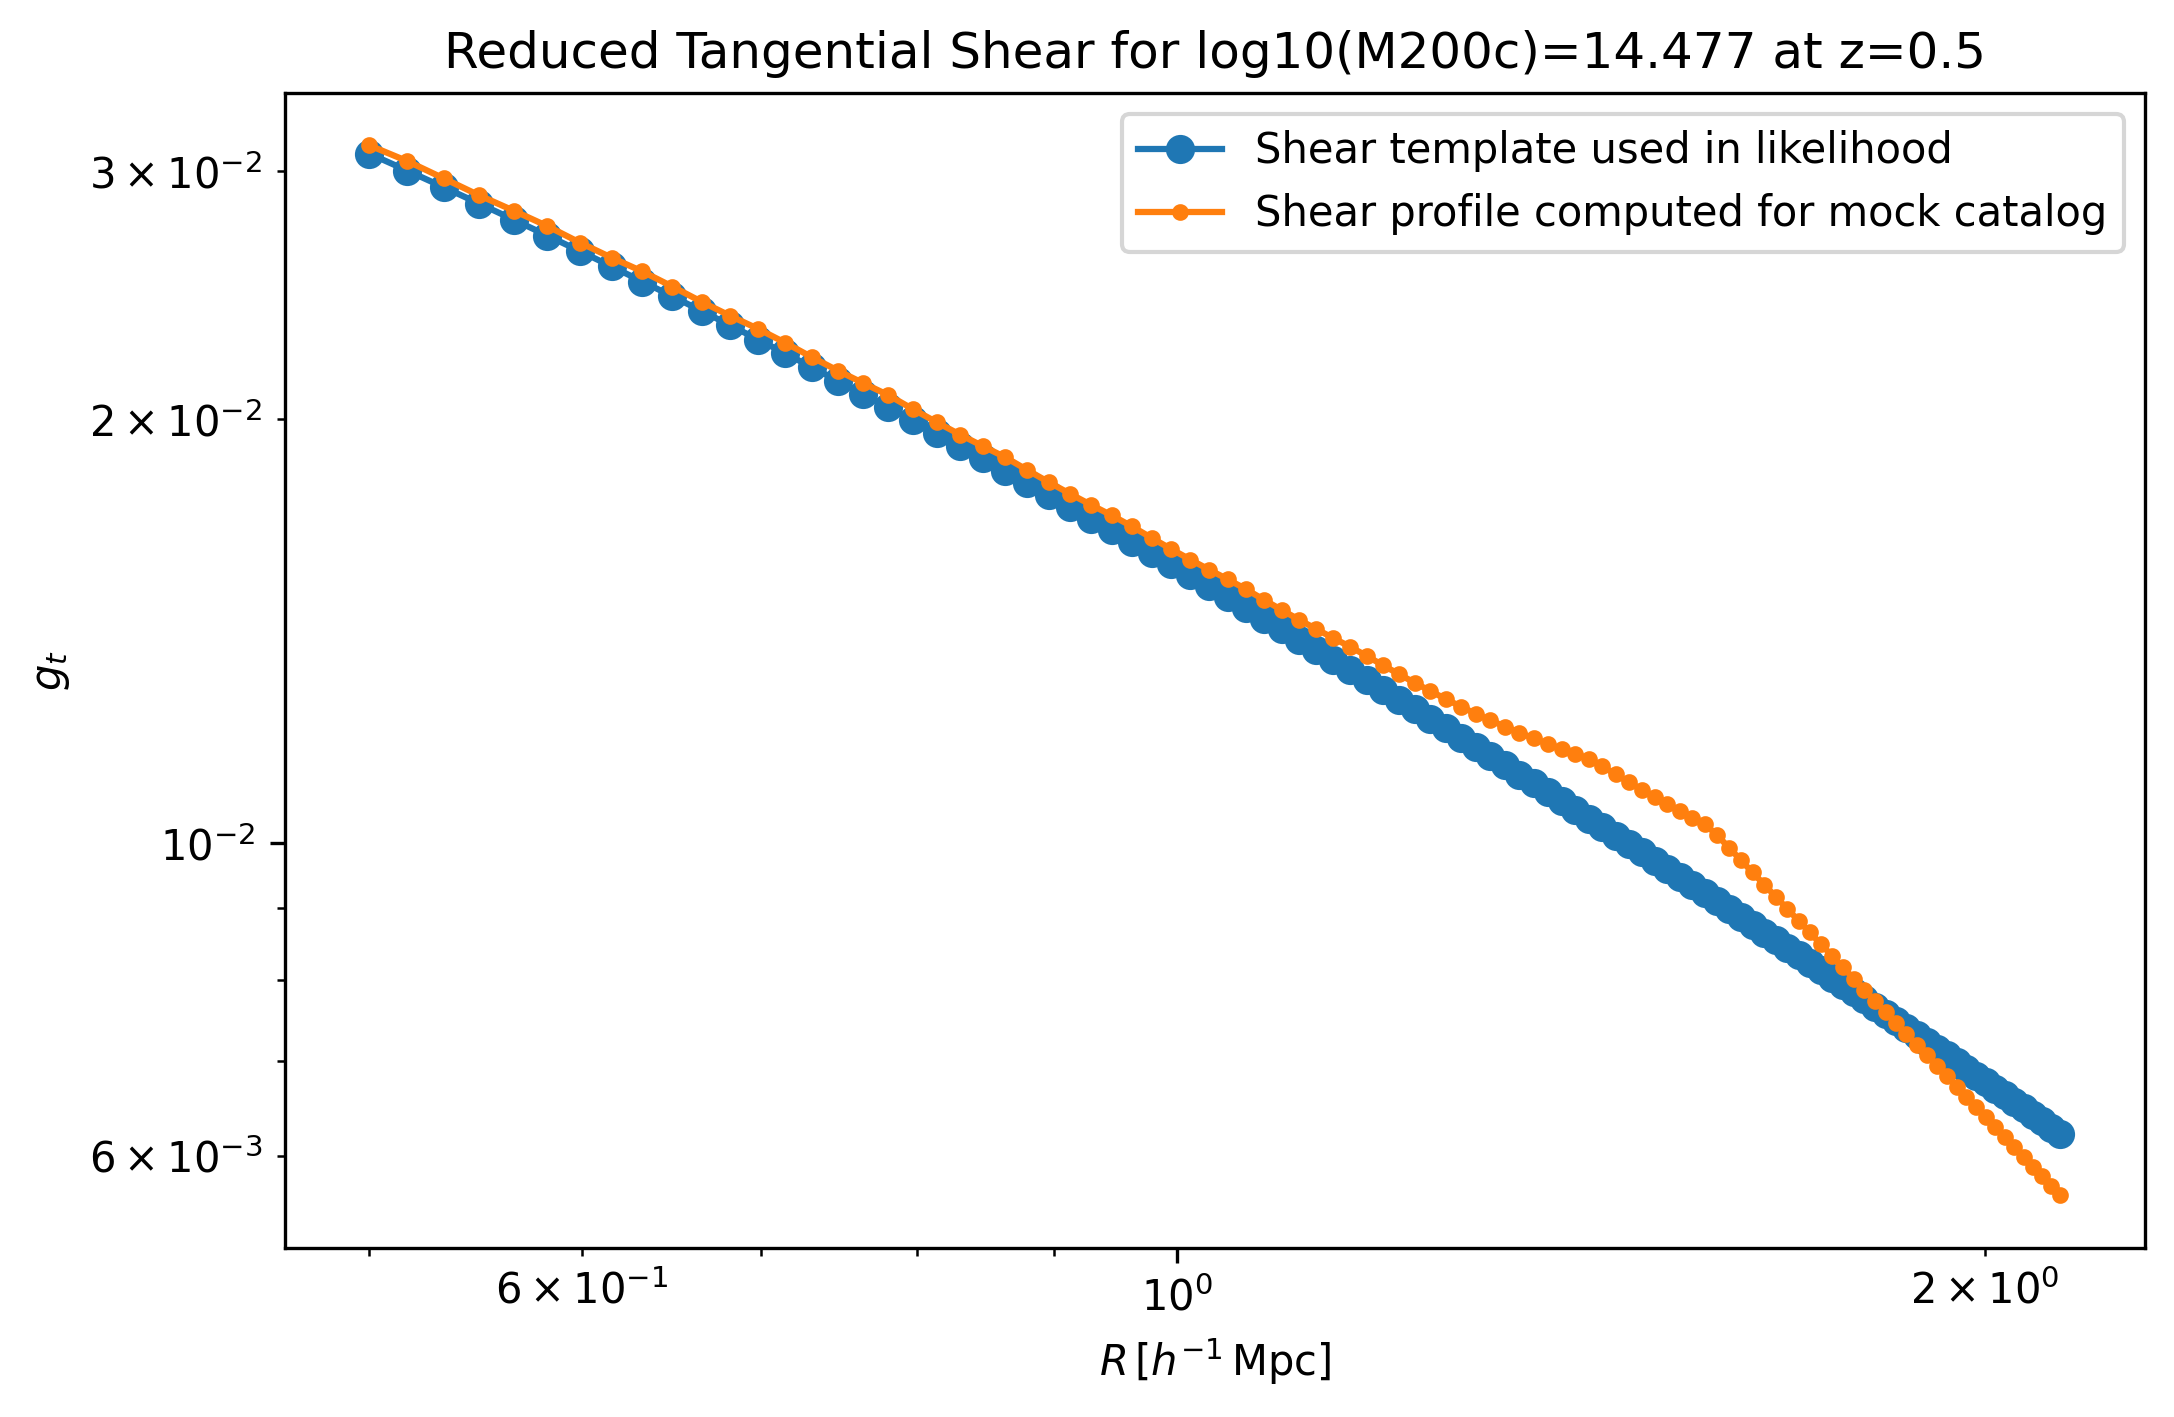

In [30]:
from wl_likelihoods import gt_nfw_from_profile

z     = 0.5
M     = 3e14    # Msol/h
omega_m = 0.143344

# ── Query cosmocnc profile at (z, M) ──────────────────────────────────────
# cosmocnc expects lnM in units of ln(M / 1e14 Msol), where M is in Msol (not Msol/h)
# so: lnM = log( (M_Msol_h / h_fid) / 1e14 )
profile = nc.get_profile_params_at_clusters(
    np.array([z]),
    np.array([[np.log(M / (h_fid * 1e14))]])   # was: M / (1e14 * h_fid) -- same, fine
)

# ── rho_crit at z ─────────────────────────────────────────────────────────
rho_crit_raw = float(np.interp(z, Z_ARR, np.asarray(nc.rho_c)))  # Msol/Mpc^3
rho_crit_h   = rho_crit_raw / h_fid**2                            # Msol/h/(Mpc/h)^3

# ── R200c and c_200c at (z, M) ────────────────────────────────────────────
M_Msol    = M / h_fid                                              # Msol
R200c_Mpc = (M_Msol / ((4*np.pi/3) * 200 * rho_crit_raw))**(1./3.)  # Mpc
r_s_Mpc   = float(profile['r_s'][0, 0])                           # Mpc (cosmocnc native)
c_200c    = R200c_Mpc / r_s_Mpc                                    # dimensionless ✅

# ── Sigma_crit at z ───────────────────────────────────────────────────────
iz_z         = np.argmin(np.abs(Z_ARR - z))
Sigma_crit_h = get_Sigma_crit_arr(omega_m)[iz_z] / h_fid          # Msol/h/(Mpc/h)^2

# ── Radial bins for z=0.5 ─────────────────────────────────────────────────
r_min  = 0.5
r_max  = 3.2 / (1. + z)
r_bins = np.linspace(r_min, r_max, 100)                            # Mpc/h

# ── Predicted shear ───────────────────────────────────────────────────────
gt_pred = gt_nfw_from_profile(
    jnp.array(r_bins),
    M,            # Msol/h
    rho_crit_h,   # Msol/h/(Mpc/h)^3
    c_200c,       # dimensionless scalar
    Sigma_crit_h  # Msol/h/(Mpc/h)^2
)

# ── Mock catalogue shear ──────────────────────────────────────────────────
iz = np.argmin(np.abs(catalogue['Z_ARR'] - z))
iM = np.argmin(np.abs(np.array(catalogue['M200c_slices'][iz]) - M))
gt_true = catalogue['shear_profiles'][iz][iM]
R_true  = np.linspace(0.5, 3.2 / (1. + z), 100)                   # Mpc/h

# ── Plot ──────────────────────────────────────────────────────────────────
plt.figure(figsize=(8, 5), dpi=300)
plt.loglog(r_bins, np.array(gt_pred), label='Shear template used in likelihood', marker='o')
plt.loglog(R_true, gt_true,           label='Shear profile computed for mock catalog', marker='.')
plt.xlabel(r"$R\,[h^{-1}\,\mathrm{Mpc}]$")
plt.ylabel(r"$g_t$")
plt.title(f"Reduced Tangential Shear for log10(M200c)={np.log10(M):.3f} at z={z}")
plt.legend()
plt.show()

1/5
2/5
3/5
4/5
5/5
Runtime: 48.2 s

Best grid point:
b_WL_0 = 0.5000
b_WL_M = 0.5000
lnL     = -18143953.0424


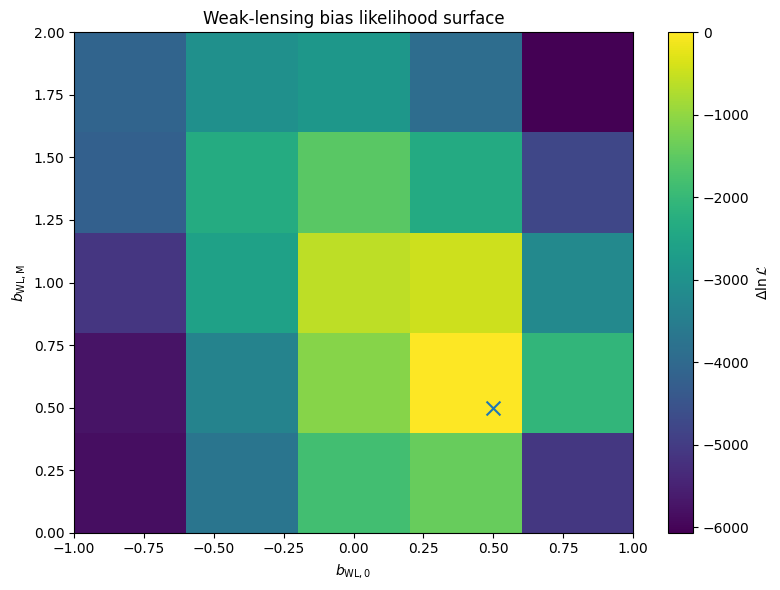

In [29]:
import pickle
import time
import numpy as np
import matplotlib.pyplot as plt

catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"

with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)

# Grid ranges
b_WL_0_grid = np.linspace(-1.0, 1.0, 5)
b_WL_M_grid = np.linspace(0.0, 2.0, 5)

lnL_grid = np.empty((len(b_WL_0_grid), len(b_WL_M_grid)))

t0 = time.time()

for i, b_WL_0 in enumerate(b_WL_0_grid):
    print(f"{i+1}/{len(b_WL_0_grid)}")
    
    for j, b_WL_M in enumerate(b_WL_M_grid):

        lnL_grid[i, j] = get_log_likelihood(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            sigma_8=0.825264573,
            A_sz=-4.1946821722123948,
            alpha_sz=0.8554747574595338,
            beta_sz=0.6853096274053094,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M,
            wl_catalogue=catalogue,
        )

print(f"Runtime: {time.time() - t0:.1f} s")

# Best-fit point
imax, jmax = np.unravel_index(np.argmax(lnL_grid), lnL_grid.shape)

print("\nBest grid point:")
print(f"b_WL_0 = {b_WL_0_grid[imax]:.4f}")
print(f"b_WL_M = {b_WL_M_grid[jmax]:.4f}")
print(f"lnL     = {lnL_grid[imax, jmax]:.4f}")

# Plot ΔlnL so dynamic range is visible
delta_lnL = lnL_grid - np.max(lnL_grid)

plt.figure(figsize=(8, 6))

im = plt.imshow(
    delta_lnL.T,
    origin="lower",
    aspect="auto",
    extent=[
        b_WL_0_grid.min(),
        b_WL_0_grid.max(),
        b_WL_M_grid.min(),
        b_WL_M_grid.max(),
    ],
)

plt.colorbar(im, label=r"$\Delta \ln \mathcal{L}$")

plt.scatter(
    b_WL_0_grid[imax],
    b_WL_M_grid[jmax],
    marker="x",
    s=100,
)

plt.xlabel(r"$b_{\rm WL,0}$")
plt.ylabel(r"$b_{\rm WL,M}$")
plt.title("Weak-lensing bias likelihood surface")

plt.tight_layout()
plt.show()